In [203]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [204]:
DATA_DIR = Path("C:/Users/Admin/OneDrive/Documents/Data Analysis project")

MatchAwayTeamInfo = pd.read_csv(DATA_DIR / "away_team.csv")
MatchAwayScoreInfo = pd.read_csv(DATA_DIR / "away_team_score.csv")
MatchEventInfo = pd.read_csv(DATA_DIR / "event.csv")
MatchHomeTeamInfo = pd.read_csv(DATA_DIR / "home_team.csv")
MatchHomeScoreInfo = pd.read_csv(DATA_DIR / "home_team_score.csv")
OddsInfo = pd.read_csv(DATA_DIR / "odds.csv")
GameInfo = pd.read_csv(DATA_DIR / "pbp.csv")
PowerInfo = pd.read_csv(DATA_DIR / "power.csv")
MatchRoundInfo = pd.read_csv(DATA_DIR / "round.csv")
MatchSeasonInfo = pd.read_csv(DATA_DIR / "season.csv")
PeriodInfo = pd.read_csv(DATA_DIR / "statistics.csv")
MatchTimeInfo = pd.read_csv(DATA_DIR / "time.csv")
MatchTournamentInfo = pd.read_csv(DATA_DIR / "tournament.csv")
MatchVenueInfo = pd.read_csv(DATA_DIR / "venue.csv")
MatchVotesInfo = pd.read_csv(DATA_DIR / "votes.csv")

In [205]:
# making sure that each playerID is registered to only one player:

all_players = pd.concat([MatchHomeTeamInfo, MatchAwayTeamInfo], ignore_index=True)

all_players['player_id'] = all_players['player_id'].astype(str).str.strip()
all_players['full_name'] = all_players['full_name'].astype(str).str.strip()

unique_players = all_players[['player_id', 'full_name']].drop_duplicates()

name_count_per_id = unique_players.groupby('player_id')['full_name'].nunique()
problematic_ids = name_count_per_id[name_count_per_id > 1]

name_mapping = unique_players.groupby('player_id')['full_name'].first().to_dict()
all_players['full_name'] = all_players['player_id'].map(name_mapping)

# Question 1

In [206]:
print(f"MatchHomeTeamInfo has {MatchHomeTeamInfo["match_id"].duplicated().sum()} duplicated match_id values")
print(f"MatchAwayTeamInfo has {MatchAwayTeamInfo["match_id"].duplicated().sum()} duplicated match_id values")

MatchHomeTeamInfo has 13221 duplicated match_id values
MatchAwayTeamInfo has 12513 duplicated match_id values


In [207]:
MatchHomeTeamInfo = MatchHomeTeamInfo.drop_duplicates()
MatchAwayTeamInfo = MatchAwayTeamInfo.drop_duplicates()

print(f"MatchHomeTeamInfo has {MatchHomeTeamInfo["match_id"].duplicated().sum()} duplicated match_id values")
print(f"MatchAwayTeamInfo has {MatchAwayTeamInfo["match_id"].duplicated().sum()} duplicated match_id values")

MatchHomeTeamInfo has 5511 duplicated match_id values
MatchAwayTeamInfo has 5191 duplicated match_id values


In [208]:
sample_id = MatchHomeTeamInfo[MatchHomeTeamInfo["match_id"].duplicated(keep=False)]["match_id"].iloc[0]
MatchHomeTeamInfo[MatchHomeTeamInfo["match_id"] == sample_id]

,match_id,name,slug,gender,user_count,residence,birthplace,height,weight,plays,turned_pro,current_prize,total_prize,player_id,current_rank,name_code,country,full_name
1,11998446,Lestienne C.,lestienne-constant,M,2032,"Paris, France","Amiens, France",1.8,72.0,right-handed,2012.0,105335.0,1404567.0,62790,99.0,LES,France,"Lestienne, Constant"
274,11998446,Lestienne C.,lestienne-constant,M,2034,"Paris, France","Amiens, France",1.8,72.0,right-handed,2012.0,98577.0,1397804.0,62790,99.0,LES,France,"Lestienne, Constant"


In [209]:
MatchHomeTeamInfo = MatchHomeTeamInfo.drop_duplicates(subset="match_id", keep="last")
MatchAwayTeamInfo = MatchAwayTeamInfo.drop_duplicates(subset="match_id", keep="last")

print(f"MatchHomeTeamInfo has {MatchHomeTeamInfo["match_id"].duplicated().sum()} duplicated match_id values")
print(f"MatchAwayTeamInfo has {MatchAwayTeamInfo["match_id"].duplicated().sum()} duplicated match_id values")

MatchHomeTeamInfo has 0 duplicated match_id values
MatchAwayTeamInfo has 0 duplicated match_id values


In [210]:
print(f"MatchHomeTeamInfo has {MatchHomeTeamInfo["player_id"].isnull().sum()} NaN values")
print(f"MatchAwayTeamInfo has {MatchAwayTeamInfo["player_id"].isnull().sum()} NaN values")

MatchHomeTeamInfo has 0 NaN values
MatchAwayTeamInfo has 0 NaN values


In [211]:
home_players = set(MatchHomeTeamInfo["player_id"].unique())
away_players = set(MatchAwayTeamInfo["player_id"].unique())

print(f"number of home_players: {len(home_players)}")
print(f"number of away_players: {len(away_players)}")

number of home_players: 2447
number of away_players: 2479


In [212]:
all_players = home_players | away_players

print(f"number of all_players: {len(all_players)}")

number of all_players: 2644


In [213]:
only_home_players = home_players - away_players
only_away_players = away_players - home_players
both_players = home_players & away_players

print(f"number of only_home_players: {len(only_home_players)}")
print(f"number of only_away_players: {len(only_away_players)}")
print(f"number of both_players: {len(both_players)}")

number of only_home_players: 165
number of only_away_players: 197
number of both_players: 2282


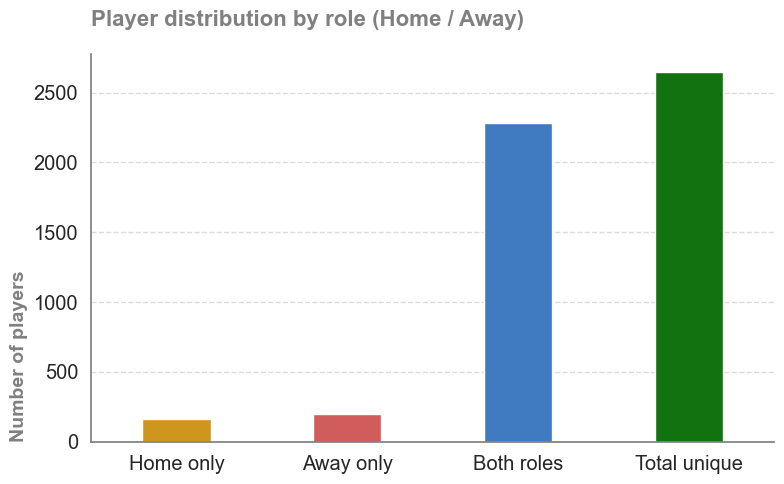

In [214]:
labels = ["Home only", "Away only", "Both roles", "Total unique"]
values = [165, 197, 2282, 2644]
colors = ["#eda100", "#e34948", "#2a78d6", "#008300"]

fig, ax= plt.subplots(figsize= (8,5)) 
ax = sns.barplot(x=labels, y=values, hue=labels, palette=colors, legend=False, width=0.4)

ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Player distribution by role (Home / Away)", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_ylabel("Number of players", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)

ax.tick_params(axis="x", color= "gray", labelsize= "large")
ax.tick_params(axis="y", color= "gray", labelsize= "large")

ax.grid(axis="y", linestyle= "dashed", alpha=0.7)

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/players_home_away.png", dpi=200)
plt.show()

In [215]:
# Player distribution by gender
num_player_by_gender= pd.concat([MatchHomeTeamInfo[["player_id", "gender"]], MatchAwayTeamInfo[["player_id", "gender"]]])

num_player_by_gender["gender"]= num_player_by_gender["gender"].str.strip()

num_player_by_gender= num_player_by_gender.groupby("player_id").first().reset_index()

In [216]:
num_player_by_gender.isna().sum()

player_id    0
gender       6
dtype: int64

In [217]:
df_gender = (num_player_by_gender.assign(gender=num_player_by_gender["gender"].fillna("Unknown"))
                                 .groupby("gender")
                                 .agg(num_player=("player_id", "count"))
                                 .reset_index())

df_gender.loc[len(df_gender)] = ["Total", df_gender["num_player"].sum()]
print(df_gender)


    gender  num_player
0        F        1234
1        M        1404
2  Unknown           6
3    Total        2644


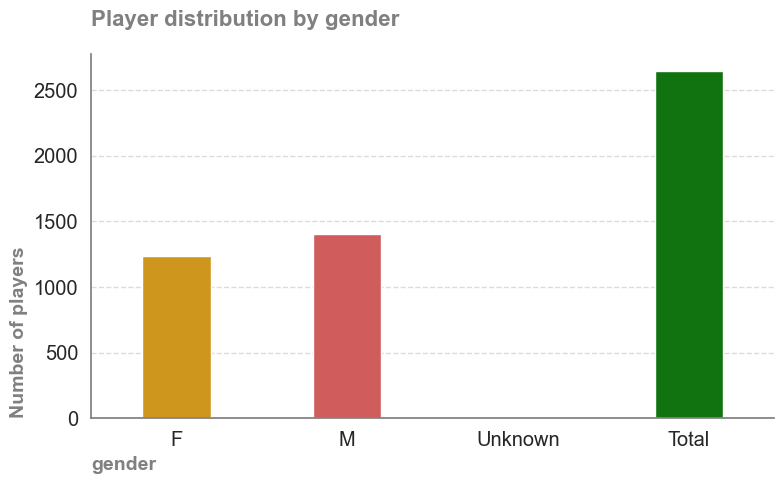

In [218]:
colors = ["#eda100", "#e34948", "#2a78d6", "#008300"]

fig, ax= plt.subplots(figsize= (8,5)) 
ax = sns.barplot(x= df_gender["gender"], y= df_gender["num_player"], hue= df_gender["gender"], palette=colors, legend=False, width=0.4)

ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Player distribution by gender", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_xlabel("gender", loc= "left", weight= "bold", color= "gray", fontsize= 14)
ax.set_ylabel("Number of players", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)

ax.tick_params(axis="x", color= "gray", labelsize= "large")
ax.tick_params(axis="y", color= "gray", labelsize= "large")

ax.grid(axis="y", linestyle= "dashed", alpha=0.7)

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Player distribution by gender.png", dpi=200)
plt.show()

**Observation**

The dataset has 2,644 unique players in total.
Of these:

1,404 players are male

1,234 players are female

6 players have an unknown gender

Also:

2,282 players appeared in both home and away roles

165 players appeared only as home

197 players appeared only as away

**Conclusion**
* The dataset has a fairly balanced gender distribution, although the number of male players is slightly higher.

* The high number of players who appear in both home and away roles shows that many players took part in multiple matches and did not have a fixed role.

* The 6 unknown gender values show that the gender data is not completely complete, so it should be used carefully in later analysis.

# Question 2

In [219]:
print(f"MatchHomeTeamInfo has {MatchHomeTeamInfo["height"].isna().sum()} NaN values")
print(f"MatchAwayTeamInfo has {MatchAwayTeamInfo["height"].isna().sum()} NaN values")

print(f"MatchHomeTeamInfo has {len(MatchHomeTeamInfo[MatchHomeTeamInfo["height"]<= 0])} non-positive height values")
print(f"MatchAwayTeamInfo has {len(MatchAwayTeamInfo[MatchAwayTeamInfo["height"]<= 0])} non-positive height values")

MatchHomeTeamInfo has 5503 NaN values
MatchAwayTeamInfo has 5170 NaN values
MatchHomeTeamInfo has 0 non-positive height values
MatchAwayTeamInfo has 0 non-positive height values


In [220]:
all_heights = pd.concat([MatchHomeTeamInfo[["player_id", "height"]], MatchAwayTeamInfo[["player_id", "height"]]])

all_heights = all_heights[
    (all_heights["height"].isna()) | (all_heights["height"] > 0)
]

heightsـconflict= (all_heights.dropna(subset=["height"]).groupby("player_id")["height"]
                                  .agg(["min", "max", "nunique"])
                                  .reset_index())

heightsـconflict[heightsـconflict["nunique"] > 1]

,player_id,min,max,nunique
182,49417,1.80,1.83,2
356,82133,1.91,1.93,2
372,89632,1.98,2.01,2
394,95801,1.91,2.08,2
771,207083,1.85,1.88,2
898,231579,1.93,1.96,2
901,232045,1.73,1.75,2
903,232059,1.98,2.01,2
964,248861,1.80,1.83,2
1242,369288,1.78,2.03,2


In [221]:
# Since some players have multiple recorded heights, we calculated and used their average height.
all_players_height = all_heights.groupby("player_id", as_index=False)["height"].mean()


missing_count = all_players_height["height"].isna().sum()
missing_pct = all_players_height["height"].isna().mean() * 100
avg_height = all_players_height["height"].mean().round(2)

print(f"Number of unique players: {len(all_players_height)}")
print(f"Missing height values: {missing_count}")
print(f"Missing height percentage: {missing_pct:.2f}%")
print(f"Average height for players with available height: {avg_height} m")

Number of unique players: 2644
Missing height values: 1301
Missing height percentage: 49.21%
Average height for players with available height: 1.82 m


In [222]:
all_players_height["height"].dropna().describe().round(2)

count    1343.00
mean        1.82
std         0.08
min         1.57
25%         1.78
50%         1.83
75%         1.88
max         2.08
Name: height, dtype: float64

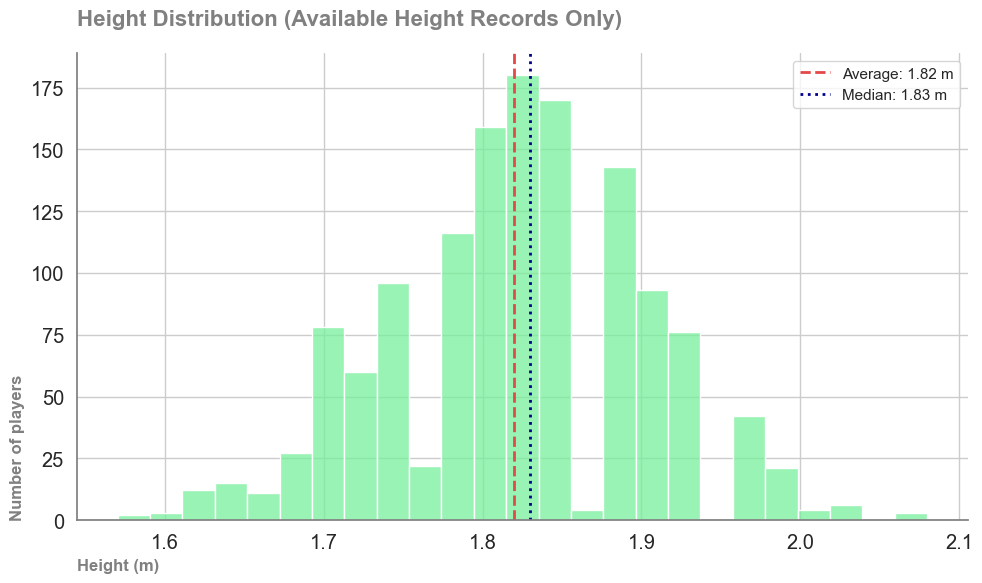

In [223]:
fig, ax = plt.subplots(figsize=(10,6))
sns.histplot(all_players_height["height"].dropna(), bins=25, color="#76f09b", ax=ax)

ax.axvline(avg_height, color="#e34948", linestyle="dashed", linewidth=2,
           label=f"Average: {avg_height} m")
median_height = all_players_height["height"].median()
ax.axvline(median_height, color="darkblue", linestyle="dotted", linewidth=2,
           label=f"Median: {median_height:.2f} m")

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Height Distribution (Available Height Records Only)", loc="left", weight="bold", color="gray", fontsize=16, pad=20)

ax.set_xlabel("Height (m)", loc= "left", weight="bold", color="gray", fontsize=12)
ax.set_ylabel("Number of players", loc= "bottom", weight="bold", color="gray", fontsize=12)

ax.tick_params(axis="x", color= "gray", labelsize= "large")
ax.tick_params(axis="y", color= "gray", labelsize= "large")

ax.legend()

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Height Distribution (Available Height Records Only.png", dpi=200)
plt.show()

In [224]:
#### Calculate height by gender
all_players_height_gender = pd.concat([MatchHomeTeamInfo[["player_id", "height", "gender"]],
                                       MatchAwayTeamInfo[["player_id", "height", "gender"]]])

all_players_height_gender["gender"]= all_players_height_gender["gender"].str.strip()

all_players_height_gender = all_players_height_gender[
    (all_players_height_gender["height"].isna()) |
    (all_players_height_gender["height"] > 0)
]

player_height_gender = (all_players_height_gender.groupby("player_id", as_index=False)
                                                 .agg({"height": "mean","gender": "first"}))


height_by_gender = (player_height_gender.dropna(subset=["height", "gender"])
                                             .groupby("gender")["height"]
                                             .agg(["mean", "count"])
                                             .round(2))

print(height_by_gender)

        mean  count
gender             
F       1.73    257
M       1.84   1085


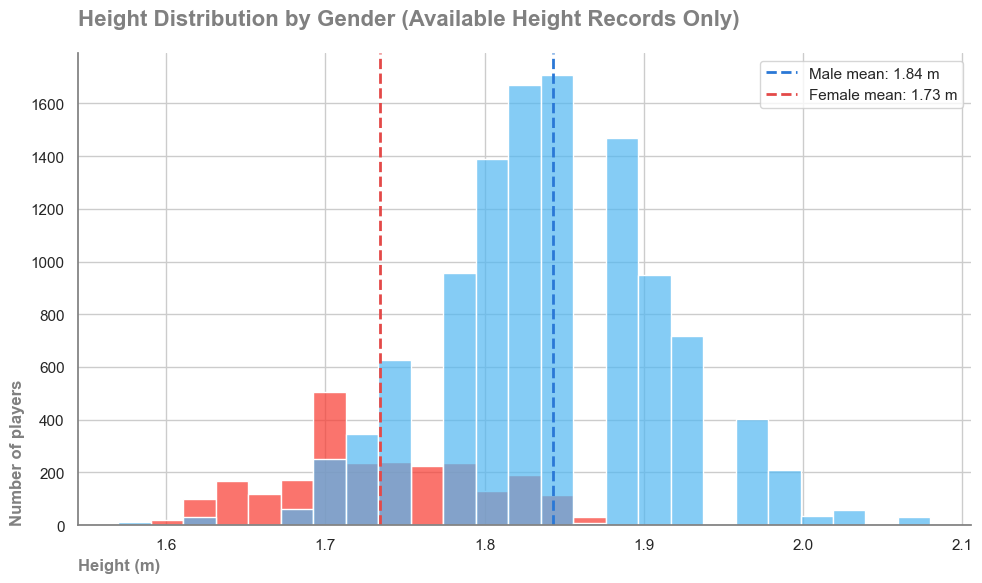

In [225]:
fig, ax = plt.subplots(figsize=(10,6))

sns.histplot(
    data=all_players_height_gender.dropna(subset=["height", "gender"]),
    x="height", hue="gender", bins=25,
    palette={"M": "#51b7f2", "F": "#f9392f"},
    ax=ax, alpha=0.7
)

mean_m = all_players_height_gender[all_players_height_gender["gender"] == "M"]["height"].mean()
mean_f = all_players_height_gender[all_players_height_gender["gender"] == "F"]["height"].mean()

ax.axvline(mean_m, color="#2a78d6", linestyle="dashed", linewidth=2, label=f"Male mean: {mean_m:.2f} m")
ax.axvline(mean_f, color="#e34948", linestyle="dashed", linewidth=2, label=f"Female mean: {mean_f:.2f} m")

ax.spines[["right", "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Height Distribution by Gender (Available Height Records Only)", loc="left", weight="bold", color="gray", fontsize=16, pad=20)

ax.set_xlabel("Height (m)", loc= "left", weight="bold", color="gray", fontsize=12)
ax.set_ylabel("Number of players", loc= "bottom", weight="bold", color="gray", fontsize=12)

ax.legend()
plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Height Distribution by Gender.png", dpi=200)
plt.show()

**Observation**

* There are 2,644 unique players in the dataset.
* Out of these, only 1,343 players have a recorded height, while 1,301 players are missing this data.
* This means about 49.21% of the height data is missing.
* The average height of the players with recorded data is 1.82 meters.
* The height distribution is in a reasonable range from 1.57 to 2.08 meters, with most players concentrated between 1.78 and 1.88 meters.
* Based on gender:
    * The average height for men is 1.84 meters.
    * The average height for women is 1.73 meters.
* The number of available height records for men (1,085) is much higher than for women (257).
* Initial checks showed that some players had different “height” values recorded across different matches. To remove this bias, the average height for each player was calculated.

**Conclusion**

* The average height for players with valid data is 1.82 meters.
* On average, male players in this dataset are taller than female players, with a difference of about 11 centimeters.
* However, nearly half of the height data is missing, so this average only represents the players who have recorded height values.
* Also, the height data coverage for women is much lower than for men, so gender comparisons should be interpreted with caution.

# Question 3

In [226]:
print(f"MatchEventInfo_df has {MatchEventInfo["match_id"].duplicated().sum()} duplicated match_id values")

MatchEventInfo = MatchEventInfo.drop_duplicates()

print(f"MatchEventInfo_df has {MatchEventInfo["match_id"].duplicated().sum()} duplicated match_id values")

MatchEventInfo_df has 18180 duplicated match_id values
MatchEventInfo_df has 5169 duplicated match_id values


In [227]:
sample_event_id = MatchEventInfo[MatchEventInfo["match_id"].duplicated(keep=False)]["match_id"].iloc[0]
MatchEventInfo[MatchEventInfo["match_id"] == sample_event_id]

,match_id,first_to_serve,home_team_seed,away_team_seed,custom_id,winner_code,default_period_count,start_datetime,match_slug,final_result_only
4138,12059167,NaN,WC,NaN,eYpdscBce,NaN,3,1707652800,briand-vadyala,True
5781,12059167,NaN,WC,NaN,eYpdscBce,2.0,3,1707652800,briand-vadyala,False


In [228]:
MatchEventInfo = MatchEventInfo.drop_duplicates(subset="match_id", keep="last")

print(f"MatchEventInfo_df has {MatchEventInfo["match_id"].duplicated().sum()} duplicated match_id values")

MatchEventInfo_df has 0 duplicated match_id values


In [229]:
MatchEventInfo["winner_code"].value_counts()

winner_code
1.0    8412
2.0    7849
Name: count, dtype: int64

In [230]:
event_home= MatchEventInfo.merge(MatchHomeTeamInfo[["match_id", "player_id"]], on="match_id", how="left") \
                    .rename(columns={"player_id": "home_player_id"})

event_full= event_home.merge(MatchAwayTeamInfo[["match_id", "player_id"]], on="match_id", how="left") \
                      .rename(columns={"player_id": "away_player_id"})


event_full["winner_player_id"] = np.where(event_full["winner_code"] == 1, event_full["home_player_id"],
                                            np.where(event_full["winner_code"] == 2, event_full["away_player_id"],pd.NA))

win_counts = (event_full["winner_player_id"].dropna().value_counts().reset_index())

win_counts.columns = ["player_id", "win_count"]

win_counts

,player_id,win_count
0,50901.0,30
1,231620.0,23
2,230049.0,23
3,341818.0,22
4,202572.0,21
...,...,...
2354,350065.0,1
2355,396006.0,1
2356,182875.0,1
2357,201729.0,1


In [231]:
names = (pd.concat([MatchHomeTeamInfo[["player_id", "full_name"]],
                    MatchAwayTeamInfo[["player_id", "full_name"]]])
            .drop_duplicates(subset="player_id"))

top10_winner = win_counts.merge(names, on="player_id").sort_values("win_count", ascending=False).head(10)

top10_winner

,player_id,win_count,full_name
0,50901.0,30,"Popko, Dmitry"
1,231620.0,23,"Chidekh, Clement"
2,230049.0,23,"Jianu, Filip Cristian"
3,341818.0,22,"Faria, Jaime"
5,152766.0,21,"Helgo, Malene"
4,202572.0,21,"Gengel, Marek"
6,238867.0,20,"Ovcharenko, Oleksandr"
8,100093.0,20,"Ferrari, Francesco"
7,205282.0,20,"Kužmová, Katarína"
9,82133.0,20,"Dellien Velasco, Murkel Alejandro"


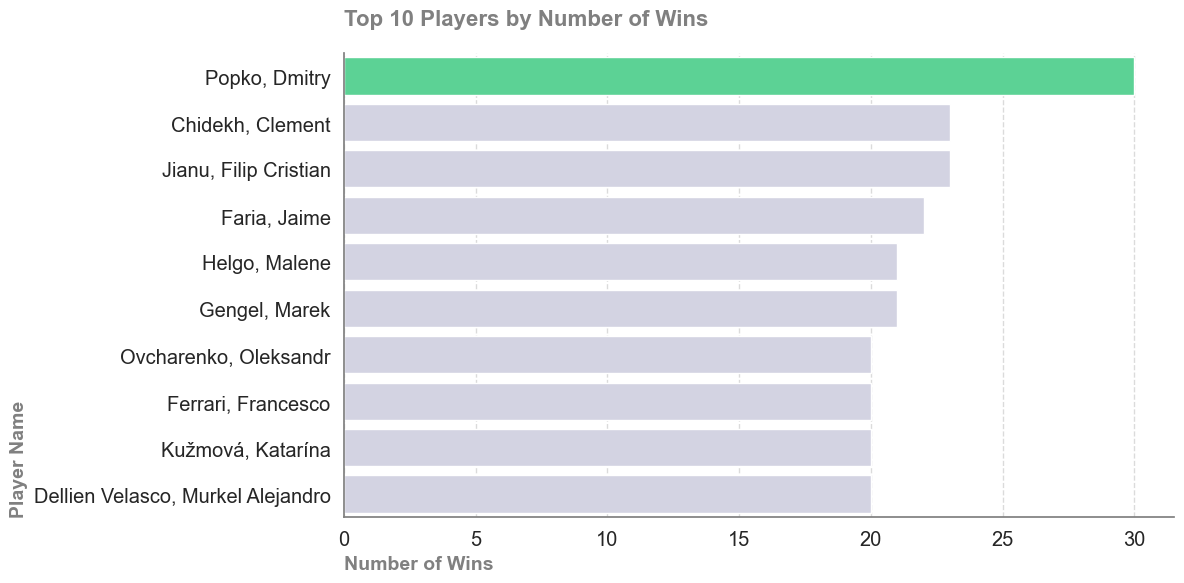

In [232]:
max_win = top10_winner["win_count"].max()
colors = ["#49E594" if x == max_win else "#d0d0e5" for x in top10_winner["win_count"]]

fig, ax= plt.subplots(figsize= (12,6)) 
ax= sns.barplot(data= top10_winner ,x= "win_count" ,y="full_name" , hue="full_name", palette= colors)

ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Top 10 Players by Number of Wins", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_xlabel("Number of Wins", loc= "left", weight= "bold", color= "gray", fontsize= 14)
ax.set_ylabel("Player Name", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)

ax.tick_params(axis="x", color= "gray", labelsize= "large")
ax.tick_params(axis="y", color= "gray", labelsize= "large")

ax.grid(axis="x", linestyle= "dashed", alpha=0.7)

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Top 10 Players by Number of Wins.png", dpi=200)
plt.show()

**Observation**

* Dmitry Popko has the highest number of wins in this dataset, with 30 victories.
* Clement Chidekh and Filip Cristian Jianu follow him, each with 23 wins.
* The win distribution among the top 10 players shows a close competition between the 2nd and 10th positions (ranging from 20 to 23 wins).

**Conclusion**

Dmitry Popko is the most successful player in terms of total wins during this period, with a significant lead (7 wins more than the second place). This suggests he is either in excellent form or has participated in many tournaments and performed successfully in them.

# Question 4

In [233]:
period_cols = ["period_1", "period_2", "period_3", "period_4", "period_5"]

print(f"MatchTimeInfo.shape: {MatchTimeInfo.shape}")

##### Checking for duplicate match_ids
print(f"MatchTimeInfo has {MatchTimeInfo["match_id"].duplicated().sum()} duplicated match_id values")
MatchTimeInfo = MatchTimeInfo.drop_duplicates(subset="match_id", keep="last")

MatchTimeInfo.shape: (35671, 7)
MatchTimeInfo has 18798 duplicated match_id values


In [234]:
##### Checking for missing values in each column
MatchTimeInfo[period_cols].isna().sum()

period_1     5784
period_2     5802
period_3    13482
period_4    16873
period_5    16873
dtype: int64

**Observation:** 

period_4 and period_5 are almost 100% empty because no matches reached the 4th or 5th set, which is normal for a best-of-3 format. Also, period_1 has 5,784 missing values.

In [235]:
##### Checking for non-positive values
for col in period_cols:
    print(f"{col} non-positive: {(MatchTimeInfo[col] < 0).sum()}")

period_1 non-positive: 0
period_2 non-positive: 2
period_3 non-positive: 0
period_4 non-positive: 0
period_5 non-positive: 0


**Observation:** 

We found two matches with negative period_2 values (for example, -16200), which does not make sense for a duration.

In [236]:
##### Checking for outliers
MatchTimeInfo[period_cols].describe()

,period_1,period_2,period_3,period_4,period_5
count,11089.000000,11071.000000,3391.000000,0.0,0.0
mean,2866.858418,3084.054738,3175.481569,NaN,NaN
std,4888.519816,5141.821530,6262.163425,NaN,NaN
min,2.000000,-16200.000000,0.000000,NaN,NaN
25%,2043.000000,2116.000000,1957.500000,NaN,NaN
50%,2515.000000,2606.000000,2602.000000,NaN,NaN
75%,3149.000000,3255.000000,3292.000000,NaN,NaN
max,172606.000000,169438.000000,152072.000000,NaN,NaN


In [237]:
MatchTimeInfo.sort_values("period_1", ascending=False).head(5)

,match_id,period_1,period_2,period_3,period_4,period_5,current_period_start_timestamp
17746,12121829,172606.0,810.0,NaN,NaN,NaN,1.709653e+09
7435,12063611,167352.0,169438.0,NaN,NaN,NaN,1.707823e+09
7428,12063589,159242.0,2155.0,794.0,NaN,NaN,1.707984e+09
7434,12063587,159144.0,161086.0,NaN,NaN,NaN,1.707824e+09
7429,12063588,158918.0,3061.0,1054.0,NaN,NaN,1.707985e+09


**Observation:**

Some values are as high as 172,606 seconds (about 48 hours), which is far beyond the world record for the longest tennis set, around 8 hours.  

In [238]:
#### Final Data Cleansing based on the observations above
MatchTimeInfo["total_duration"] = MatchTimeInfo[period_cols].sum(axis=1, skipna=True)

# Removing invalid values:
# - Negative 'period' or values exceeding 8 hours (world record for longest set).
# - Total duration less than 5 minutes (matches with no temporal data).
# - Total duration exceeding the world record (~11 hours)

MAX_PERIOD = 30000  
MIN_DURATION = 300
MAX_TOTAL_DURATION = 44000

invalid_period = (MatchTimeInfo[period_cols] < 0).any(axis=1) | (MatchTimeInfo[period_cols] > MAX_PERIOD).any(axis=1)
invalid_duration = (MatchTimeInfo["total_duration"] < MIN_DURATION) | (MatchTimeInfo["total_duration"] > MAX_TOTAL_DURATION)

MatchTimeInfo_clean = MatchTimeInfo[~(invalid_period | invalid_duration)].copy()
MatchTimeInfo_clean["duration_hours"]= (MatchTimeInfo_clean["total_duration"] / 3600).round(2)

print(f"Raw Matches: {len(MatchTimeInfo)}")
print(f"Cleaned Matches: {len(MatchTimeInfo_clean)}")

Raw Matches: 16873
Cleaned Matches: 10997


In [239]:
longest_match = MatchTimeInfo_clean.sort_values("total_duration", ascending=False).head(1)
longest_match 

,match_id,period_1,period_2,period_3,period_4,period_5,current_period_start_timestamp,total_duration,duration_hours
30640,12177252,17974.0,2129.0,22730.0,NaN,NaN,1.711018e+09,42833.0,11.9


In [240]:
print(f"longest_match duration: {longest_match["duration_hours"]} hours")

longest_match duration: 30640    11.9
Name: duration_hours, dtype: float64 hours


In [241]:
# Duration Match By Gender
home_gender = MatchHomeTeamInfo.set_index('match_id')['gender']
away_gender = MatchAwayTeamInfo.set_index('match_id')['gender']

gender_lookup = home_gender.combine_first(away_gender).reset_index()
gender_lookup

time_gender_df = MatchTimeInfo_clean.merge(gender_lookup, on="match_id", how="left")
longest_match_gender= time_gender_df.groupby("gender").agg(duration_hours_gender= ("duration_hours" , "max")).reset_index()
longest_match_gender

,gender,duration_hours_gender
0,F,10.1
1,M,11.9


C:\Users\Admin\AppData\Local\Temp\ipykernel_19400\2953873799.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data= longest_match_gender, x="gender", y="duration_hours_gender",


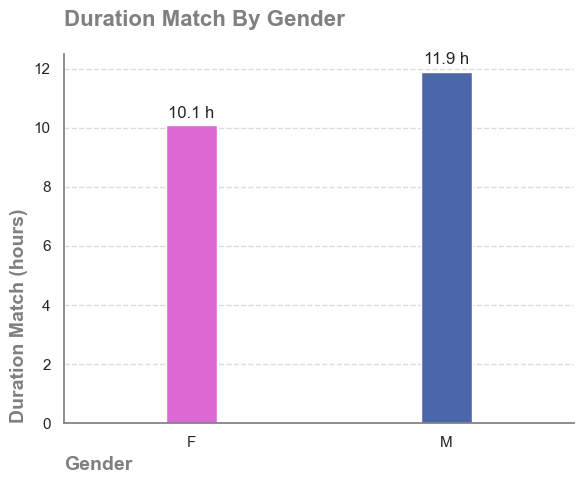

In [242]:
plt.figure(figsize=(6,5))

ax = sns.barplot(data= longest_match_gender, x="gender", y="duration_hours_gender",
                 palette=("#f056e4" , "#3d60b8"),
                 width=0.2)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f h', padding=3)

ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Duration Match By Gender", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_xlabel("Gender", loc= "left", weight= "bold", color= "gray", fontsize= 14)
ax.set_ylabel("Duration Match (hours)", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)


ax.grid(axis="y", linestyle= "dashed", alpha=0.7)

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Duration Match.png", dpi=200)
plt.show()

**Observation**

* The longest recorded match was 11.9 hours for men and 10.1 hours for women.
* About 35% of the raw data was removed because of unrealistic values (negative time, system errors causing extreme durations, or very short matches) to keep the analysis valid.

**Conclusion**

Men’s matches generally have the potential to last longer than women’s matches (with a difference of about 2 hours in the records). This could be due to differences in match formats (such as “Best of 5” sets in some major men’s tournaments) or longer rallies at this level.

# Question 5

In [243]:
print(f"MatchHomeScoreInfo has {MatchHomeScoreInfo["match_id"].duplicated().sum()} duplicated match_id values")
print(f"MatchAwayScoreInfo has {MatchAwayScoreInfo["match_id"].duplicated().sum()} duplicated match_id values")

MatchHomeScoreInfo has 18291 duplicated match_id values
MatchAwayScoreInfo has 18180 duplicated match_id values


In [244]:
MatchHomeScoreInfo = MatchHomeScoreInfo.drop_duplicates(subset="match_id", keep="last")
MatchAwayScoreInfo = MatchAwayScoreInfo.drop_duplicates(subset="match_id", keep="last")

print(f"MatchHomeScoreInfo has {MatchHomeScoreInfo["match_id"].duplicated().sum()} duplicated match_id values")
print(f"MatchAwayScoreInfo has {MatchAwayScoreInfo["match_id"].duplicated().sum()} duplicated match_id values")

MatchHomeScoreInfo has 0 duplicated match_id values
MatchAwayScoreInfo has 0 duplicated match_id values


In [245]:
period_cols = ["period_1", "period_2", "period_3", "period_4", "period_5"]

home = MatchHomeScoreInfo[["match_id"] + period_cols].copy()
away = MatchAwayScoreInfo[["match_id"] + period_cols].copy()

home["sets_home"] = home[period_cols].notna().sum(axis=1)
away["sets_away"] = away[period_cols].notna().sum(axis=1)

sets_df = home[["match_id", "sets_home"]].merge(away[["match_id", "sets_away"]],on="match_id",how="outer")

In [246]:
sets_df["sets_played"] = sets_df[["sets_home", "sets_away"]].max(axis=1)

In [247]:
# Dropping missing values
valid = sets_df[sets_df["sets_played"] > 0].copy()

counts = valid["sets_played"].value_counts().reset_index()
counts.columns = ["sets_played", "count"]
counts["percentage"] = (counts["count"] / counts["count"].sum() * 100).round(2)
counts = counts.sort_values("sets_played").reset_index(drop=True)

counts

,sets_played,count,percentage
0,1,117,0.72
1,2,11625,71.78
2,3,4453,27.50


C:\Users\Admin\AppData\Local\Temp\ipykernel_19400\3108181224.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=counts, x="sets_played", y="percentage",


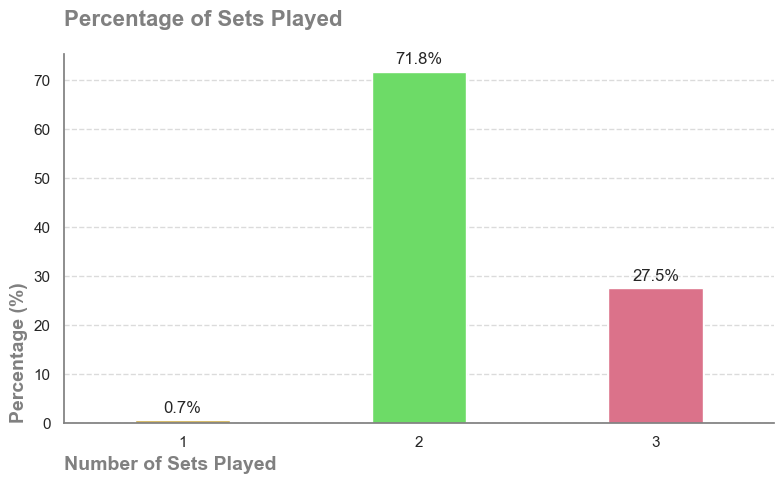

In [248]:
plt.figure(figsize=(8,5))

ax = sns.barplot(data=counts, x="sets_played", y="percentage",
                 palette=("#e4b730" , "#5cee54" , "#ed6081"),
                 width=0.4)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)

ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Percentage of Sets Played", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_xlabel("Number of Sets Played", loc= "left", weight= "bold", color= "gray", fontsize= 14)
ax.set_ylabel("Percentage (%)", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)


ax.grid(axis="y", linestyle= "dashed", alpha=0.7)

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Percentage of Sets Played.png", dpi=200)
plt.show()

In [249]:
# Sets Played by Gender
home_gender = MatchHomeTeamInfo.set_index('match_id')['gender']
away_gender = MatchAwayTeamInfo.set_index('match_id')['gender']

gender_lookup = home_gender.combine_first(away_gender).reset_index()

In [250]:
valid_gender= valid.merge(gender_lookup[["match_id", "gender"]], on= "match_id", how= "left")

sets_played_gender= valid_gender.groupby(["gender", "sets_played"]).agg(count_sets_played= ("sets_played", "count")).reset_index()

sets_played_gender["percentage"] = (sets_played_gender["count_sets_played"] / 
                                    sets_played_gender.groupby("gender")["count_sets_played"].transform("sum")
                                    ) * 100


sets_played_gender["percentage"] = sets_played_gender["percentage"].round(2)
print(sets_played_gender)

  gender  sets_played  count_sets_played  percentage
0      F            1                 52        0.90
1      F            2               4137       71.45
2      F            3               1601       27.65
3      M            1                 60        0.76
4      M            2               5581       70.48
5      M            3               2278       28.77


In [251]:
print("Matches with missing gender after merge:", valid_gender["gender"].isnull().sum())
print("Coverage Percentage:", (valid_gender["gender"].notna().sum() / len(valid_gender) * 100).round(2))

Matches with missing gender after merge: 2486
Coverage Percentage: 84.65


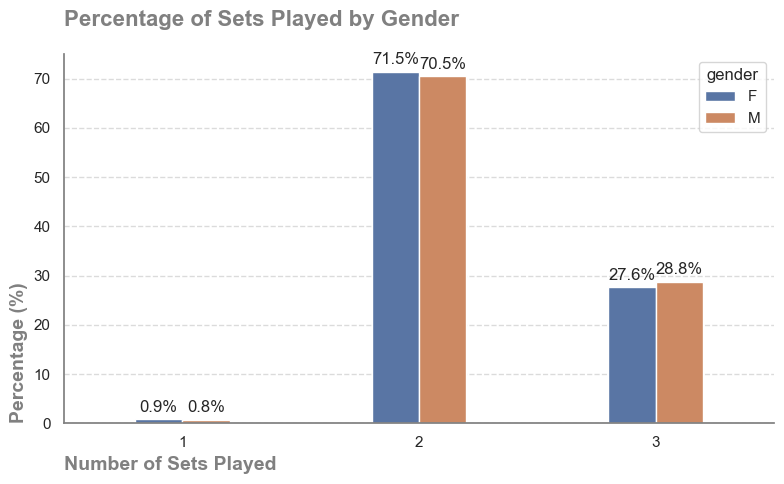

In [252]:
plt.figure(figsize=(8,5))

ax = sns.barplot(data=sets_played_gender, x='sets_played', y='percentage', hue='gender',  width=0.4)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3)


ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Percentage of Sets Played by Gender", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_xlabel("Number of Sets Played", loc= "left", weight= "bold", color= "gray", fontsize= 14)
ax.set_ylabel("Percentage (%)", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)


ax.grid(axis="y", linestyle= "dashed", alpha=0.7)

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Percentage of Sets Played by gender.png", dpi=200)
plt.show()

**Observation**

* About 72% of the matches ended in 2 sets.
* About 27% of the matches went to 3 sets.
* 1-set matches are very rare and are likely outliers or unusual cases.
* In the gender category, 84.65% of the records were available for analysis, while 15.35% still had missing gender data.

**Conclusion**

The most common match format in this dataset is 2 sets. There is no significant difference in the set distribution between men and women. The presence of incomplete records and 1-set matches suggests that the data needs further validation.

# Question 6

In [253]:
# Method 1: Number of successful players by country
# successful player = a player who has won at least one tournament

event = MatchEventInfo[["match_id", "winner_code"]]
tournament = MatchTournamentInfo[["match_id", "tournament_id"]]
round_info = MatchRoundInfo[["match_id", "name", "slug"]]

home = MatchHomeTeamInfo[["match_id", "player_id", "full_name", "country"]].rename(columns={
    "player_id": "home_player_id",
    "full_name": "home_player_name",
    "country": "home_country"
})

away = MatchAwayTeamInfo[["match_id", "player_id", "full_name", "country"]].rename(columns={
    "player_id": "away_player_id",
    "full_name": "away_player_name",
    "country": "away_country"
})

df = (
    event.merge(tournament, on="match_id", how="inner")
         .merge(round_info, on="match_id", how="inner")
         .merge(home, on="match_id", how="left")
         .merge(away, on="match_id", how="left")
)


finals = df[
    df["name"].str.lower().eq("final") | df["slug"].str.lower().eq("final")
].copy()


finals["winner_player_id"] = np.where(finals["winner_code"] == 1, finals["home_player_id"], finals["away_player_id"])

finals["winner_name"] = np.where(finals["winner_code"] == 1, finals["home_player_name"], finals["away_player_name"])

finals["winner_country"] = np.where(finals["winner_code"] == 1, finals["home_country"], finals["away_country"])

finals["winner_country"] = finals["winner_country"].str.strip()

champion_players = (finals.dropna(subset=["winner_player_id", "winner_country"])[["winner_player_id", "winner_name", "winner_country"]]
                          .drop_duplicates(subset="winner_player_id"))

In [254]:
# Count how many successful players each country produced
successful_players_by_country = (champion_players.groupby("winner_country")["winner_player_id"]
                                                 .nunique()
                                                 .reset_index(name="champion_players")
                                                 .sort_values("champion_players", ascending=False))

top10_successful_countries = successful_players_by_country.head(10)

top10_successful_countries

,winner_country,champion_players
18,France,17
49,USA,16
27,Italy,14
44,Spain,12
40,Russia,11
1,Australia,11
0,Argentina,10
41,Slovakia,8
20,Germany,7
13,Czech Republic,7


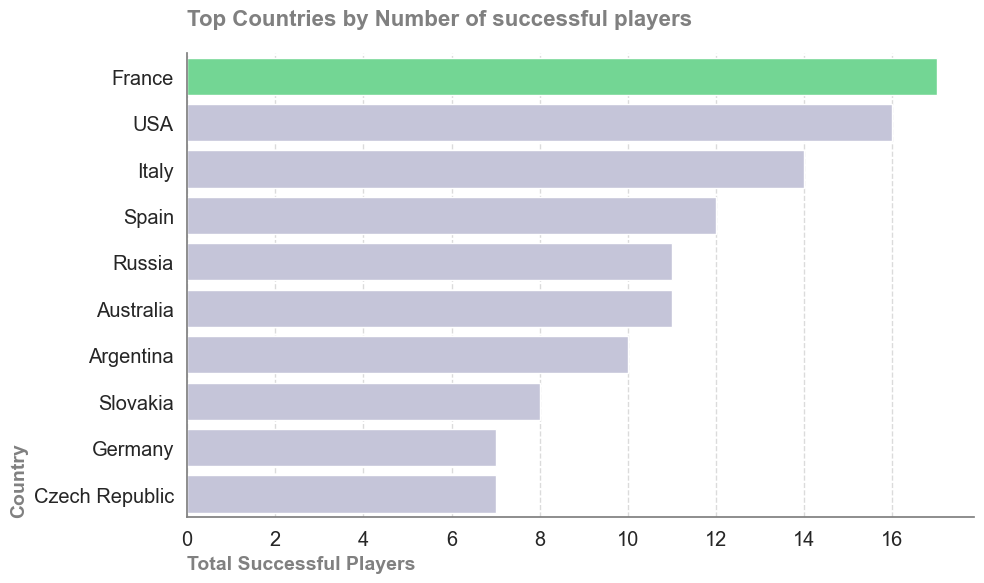

In [255]:
successful_countries_max = top10_successful_countries["champion_players"].max()
colors = ["#62E78F" if x == successful_countries_max else "#c2c2dc" for x in top10_successful_countries["champion_players"]]

fig, ax= plt.subplots(figsize= (10,6)) 
ax= sns.barplot(data= top10_successful_countries ,x= "champion_players" ,y="winner_country" , hue="winner_country", palette= colors)

ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Top Countries by Number of successful players", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_xlabel("Total Successful Players", loc= "left", weight= "bold", color= "gray", fontsize= 14)
ax.set_ylabel("Country", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)

ax.tick_params(axis="x", color= "gray", labelsize= "large")
ax.tick_params(axis="y", color= "gray", labelsize= "large")

ax.grid(axis="x", linestyle= "dashed", alpha=0.7)

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Top Countries by Number of successful players.png", dpi=200)
plt.show()

In [256]:
# method 2 (Tournament championship)

event= MatchEventInfo[["match_id", "winner_code"]]
tornoment= MatchTournamentInfo[["match_id", "tournament_id", "tournament_name"]]
round_info= MatchRoundInfo[["match_id", "name", "slug"]] 

home= (MatchHomeTeamInfo[["match_id", "player_id", "full_name", "country"]]
            .rename(columns={"player_id": "home_player_id", "full_name": "home_player_name", "country": "home_country"}))

away= (MatchAwayTeamInfo[["match_id", "player_id", "full_name", "country"]]  
            .rename(columns={"player_id": "away_player_id", "full_name": "away_player_name", "country": "away_country"}))

df= (
    event.merge(tornoment, on="match_id", how="inner")
         .merge(round_info, on="match_id", how="inner")
         .merge(home, on="match_id", how="left")
         .merge(away, on="match_id", how="left")
)


finals = df[df["name"].str.lower().eq("final") | df["slug"].str.lower().eq("final")].copy()

finals["winner_country"] = np.where(finals["winner_code"] == 1, finals["home_country"], finals["away_country"])


country_wins = (finals.groupby("winner_country")["tournament_id"]
                      .nunique()
                      .reset_index(name="tournaments_won")
                      .sort_values("tournaments_won", ascending=False))


top10_country_wins= country_wins.head(10)
top10_country_wins

,winner_country,tournaments_won
18,France,21
49,USA,19
27,Italy,15
44,Spain,14
1,Australia,14
13,Czech Republic,13
0,Argentina,13
40,Russia,11
41,Slovakia,11
29,Kazakhstan,9


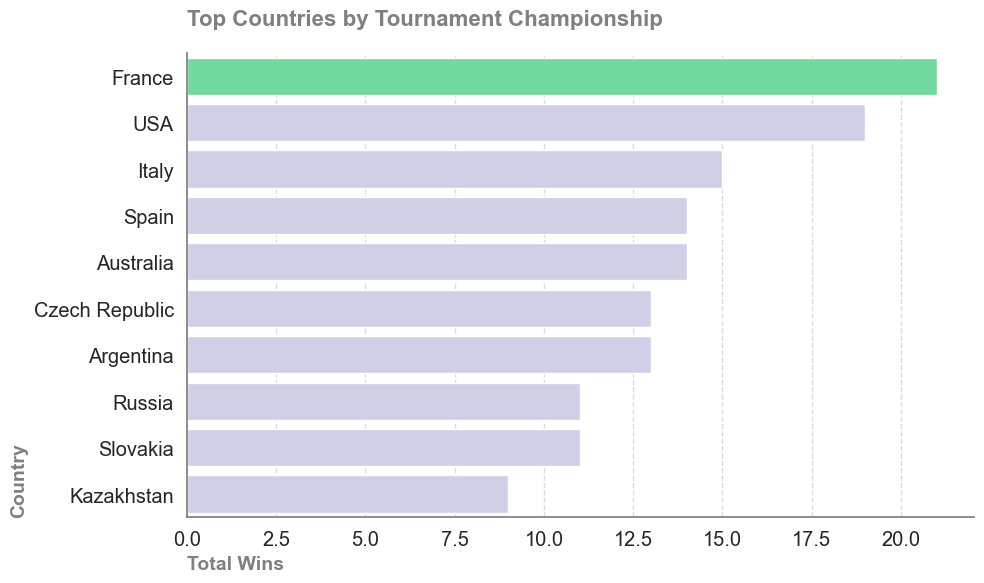

In [257]:
country_wins_max = top10_country_wins["tournaments_won"].max()
colors = ["#5FEB9A" if x == country_wins_max else "#cbcbe9" for x in top10_country_wins["tournaments_won"]]

fig, ax= plt.subplots(figsize= (10,6)) 
ax= sns.barplot(data= top10_country_wins ,x= "tournaments_won" ,y="winner_country" , hue="winner_country", palette= colors)

ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Top Countries by Tournament Championship", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_xlabel("Total Wins", loc= "left", weight= "bold", color= "gray", fontsize= 14)
ax.set_ylabel("Country", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)

ax.tick_params(axis="x", color= "gray", labelsize= "large")
ax.tick_params(axis="y", color= "gray", labelsize= "large")

ax.grid(axis="x", linestyle= "dashed", alpha=0.7)

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Top Countries by Tournament Championship.png", dpi=200)
plt.show()

In [258]:
# method 3 (prize)
all_prize= (pd.concat([MatchHomeTeamInfo[["player_id", "total_prize", "country"]], MatchAwayTeamInfo[["player_id", "total_prize", "country"]]]))
all_prize["country"]= all_prize["country"].str.strip()

In [259]:
player_prize = (
    all_prize.sort_values("total_prize", ascending=False)
    .dropna(subset=["player_id", "country", "total_prize"])
    .drop_duplicates(subset="player_id", keep="first")
)


In [260]:
prize_by_country= (player_prize.dropna(subset=["total_prize"])
                               .groupby("country")
                               .agg(median_prize=("total_prize", "median"),
                                    avg_prize= ("total_prize", "mean"),
                                    num_players=("player_id", "count"), 
                                   )
                               .reset_index()
                               .sort_values("avg_prize", ascending= True))

In [261]:
MIN_PLAYERS = 10
reliable_prize = prize_by_country[prize_by_country["num_players"] >= MIN_PLAYERS]

reliable_prize["avg_prize"] = reliable_prize["avg_prize"].round(0)
reliable_prize["median_prize"] = reliable_prize["median_prize"].round(0)

top10_country_prize= reliable_prize.sort_values("avg_prize", ascending=False).head(10)
top10_country_prize

C:\Users\Admin\AppData\Local\Temp\ipykernel_19400\1976207284.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reliable_prize["avg_prize"] = reliable_prize["avg_prize"].round(0)
C:\Users\Admin\AppData\Local\Temp\ipykernel_19400\1976207284.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  reliable_prize["median_prize"] = reliable_prize["median_prize"].round(0)


,country,median_prize,avg_prize,num_players
80,Serbia,26335.0,4641984.0,39
24,Denmark,30946.0,3248620.0,12
8,Belarus,59271.0,3058046.0,20
21,Croatia,100684.0,2087776.0,26
86,Spain,41490.0,2003657.0,98
52,Latvia,77046.0,1991417.0,10
34,Greece,32238.0,1890617.0,20
15,Canada,69709.0,1794508.0,29
49,Kazakhstan,98387.0,1669646.0,19
74,Poland,24862.0,1376898.0,36


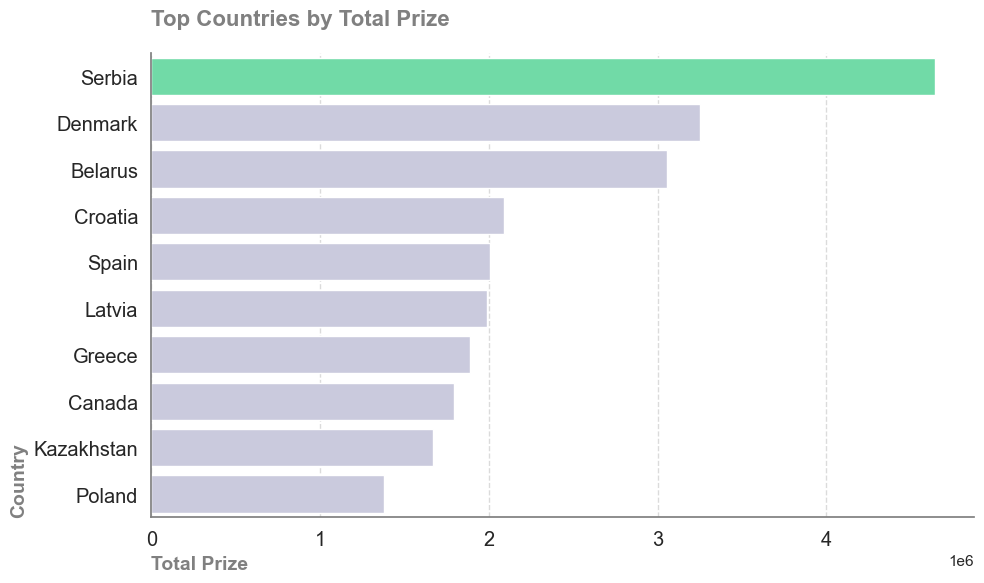

In [262]:
country_prize_max = top10_country_prize["avg_prize"].max()
colors = ["#60EBA8" if x == country_prize_max else "#c7c7e0" for x in top10_country_prize["avg_prize"]]

fig, ax= plt.subplots(figsize= (10,6)) 
ax= sns.barplot(data= top10_country_prize ,x= "avg_prize" ,y="country" , hue="country", palette= colors)

ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Top Countries by Total Prize", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_xlabel("Total Prize", loc= "left", weight= "bold", color= "gray", fontsize= 14)
ax.set_ylabel("Country", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)

ax.tick_params(axis="x", color= "gray", labelsize= "large")
ax.tick_params(axis="y", color= "gray", labelsize= "large")

ax.grid(axis="x", linestyle= "dashed", alpha=0.7)

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Top Countries by Total Prize.png", dpi=200)
plt.show()

**Observation**

Three different methods show three different perspectives of success:

**Method 1 — Number of Unique Successful Players:**

France ranks first with 17 champion players, followed by the USA with 16 and Italy with 14.

This means France has the highest number of individual players who have won at least one tournament.

**Method 2 — Total Tournament Titles:**

France is again in first place with 21 titles, followed by the USA with 19 and Italy with 15.

This shows that France not only has more successful players but also performs very strongly in terms of total trophies won.

**Method 3 — Player Prize Money:**

In this category, Serbia ranks first instead of France.

This suggests that Serbia likely has higher-earning or “superstar” players, even if they have fewer individual champions compared to France.

**Conclusion**

If we define success by the number of successful players and total titles, France is the most successful country in this dataset.
However, if we measure success based on player earnings, Serbia is more prominent.

# Question 7:

In [263]:
PeriodInfo['statistic_name']=PeriodInfo['statistic_name'].str.strip()
PeriodInfo['period']=PeriodInfo['period'].str.strip()

Aces=PeriodInfo[(PeriodInfo['statistic_name'] == 'aces') & (PeriodInfo['period']=='ALL')].copy()
Aces=Aces.drop_duplicates(subset=['match_id'] , keep='last')
avg_home_aces = Aces['home_value'].mean()
avg_away_aces = Aces['away_value'].mean()
print(f"The average number of aces per home match {avg_home_aces:.2f}")
print(f"The average number of aces per away match {avg_away_aces:.2f}")

Aces['total_aces_in_match'] = Aces['home_value'] + Aces['away_value']
if 'match_id' in Aces.columns:
    average_aces_per_match = Aces['total_aces_in_match'].mean()
    print(f"The average number of aces per match:{average_aces_per_match:.2f}")

The average number of aces per home match 2.72
The average number of aces per away match 2.67
The average number of aces per match:5.39


**Observation**
* The average number of aces per home match is 2.72.
* The average number of aces per away match is 2.67.
* The combined average number of aces per match across all settings is 5.39.

**Conclusion**

The average number of aces per match = 5.39.
The data indicates that the venue has a negligible impact on performance, as the difference between home and away matches is only 0.05. This suggests a high level of consistency in serving performance regardless of whether the match is played at home or away.

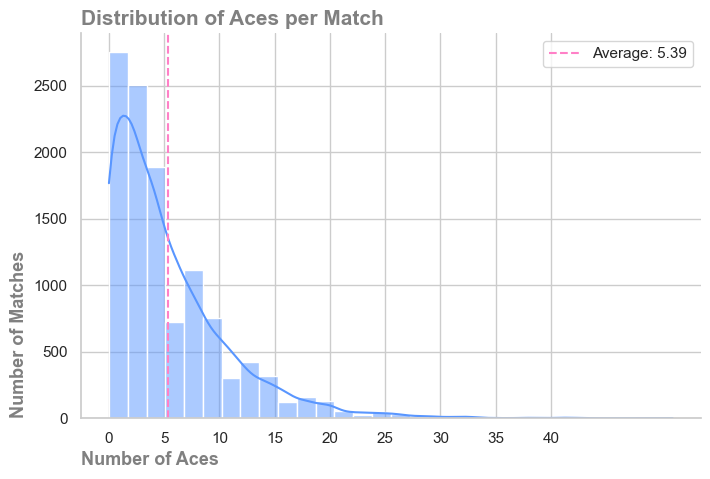

In [264]:
# Chart
plt.figure(figsize=(8,5))

sns.histplot(Aces['total_aces_in_match'].dropna(), bins=30, kde=True, color='#5996FF')

plt.axvline(Aces['total_aces_in_match'].mean(), color='#FF80C7', linestyle='--', label=f'Average: {Aces['total_aces_in_match'].mean():.2f}')

plt.title('Distribution of Aces per Match',loc='left' , color='gray' , weight='bold' , fontsize=15)

plt.xlabel('Number of Aces', loc='left' , color='gray' , weight='bold' , fontsize=13)
plt.ylabel('Number of Matches',loc='bottom' , color='gray' , weight='bold' , fontsize=13)

plt.xticks(range(0, 41,5))


sns.despine(right=True, top=True)
ax.spines[["left" , "bottom"]].set_color("gray")

plt.legend()
#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Distribution of Aces per Match.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation**

The distribution of aces per match is strongly right-skewed, with the highest frequency of matches occurring in the 0–2 ace range (approximately 2,750 matches).
The frequency decreases sharply as the number of aces increases, with a long tail extending to approximately 40 aces in rare, exceptional matches.
The calculated mean of 5.39 sits noticeably higher than the mode (1–2 aces).

**Conclusion**

The mean (5.39) is not an accurate representation of a “typical” match due to the influence of rare, high-ace outliers—likely matches featuring exceptionally strong servers or long, tiebreak-heavy sets. Consequently, the median or mode would provide a more reliable measure of central tendency for this dataset, as the bulk of the observations are heavily concentrated at the lower end of the spectrum.

In [265]:
# Aces by gender

aces_info = PeriodInfo[(PeriodInfo['statistic_name'] == 'aces') & (PeriodInfo['period'] == 'ALL')].copy()
aces_info = aces_info.drop_duplicates(subset=['match_id'], keep='last')

home_gender = MatchHomeTeamInfo[['match_id', 'gender']].drop_duplicates(subset=['match_id'])
away_gender = MatchAwayTeamInfo[['match_id', 'gender']].drop_duplicates(subset=['match_id'])


aces_home = aces_info[['match_id', 'home_value', 'away_value']].merge(home_gender, on='match_id', how='left').rename(columns={'gender': 'home_gender'})

aces_gender = aces_home.merge(away_gender, on='match_id', how='left').rename(columns={'gender': 'away_gender'})

aces_gender['home_value'] = pd.to_numeric(aces_gender['home_value'], errors='coerce')
aces_gender['away_value'] = pd.to_numeric(aces_gender['away_value'], errors='coerce')

home_part = aces_gender[['match_id', 'home_value', 'home_gender']].rename(columns={'home_value': 'aces', 'home_gender': 'gender'})
away_part = aces_gender[['match_id','away_value', 'away_gender']].rename(columns={'away_value': 'aces', 'away_gender': 'gender'})

all_aces = pd.concat([home_part, away_part]).dropna(subset=['aces', 'gender'])

final_result = all_aces.groupby('gender')['aces'].mean()

print("Average Aces by Gender:")
print(final_result)

Average Aces by Gender:
gender
F    1.803465
M    3.670711
Name: aces, dtype: float64


**Observation**

* Female matches (F) have an average of 1.80 aces per match.
* Male matches (M) have an average of 3.67 aces per match.

**Conclusion**

The average number of aces per match is significantly higher in men’s matches compared to women’s matches. This disparity suggests that male players typically serve at a higher velocity or with more effectiveness in securing direct points, resulting in more than double the average ace count seen in women’s matches.

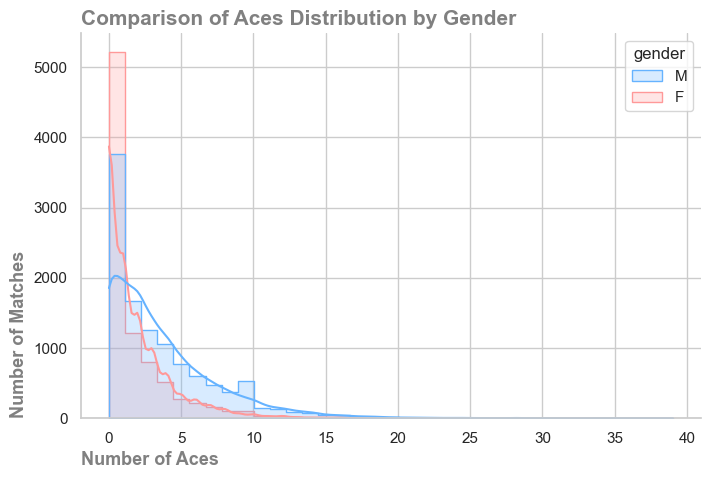

In [266]:
plt.figure(figsize=(8,5))
sns.histplot(data=all_aces, x='aces', hue='gender', kde=True, element="step",bins=35, palette=['#66b3ff', '#ff9999'])

plt.ylabel('Number of Matches',loc='bottom' , color='gray' , weight='bold' , fontsize=13)
plt.xlabel('Number of Aces',loc='left' , color='gray' , weight='bold' , fontsize=13)

plt.title('Comparison of Aces Distribution by Gender', loc='left' , color='gray' , weight='bold' , fontsize=15)

sns.despine(top=True, right=True)
ax.spines[["left" , "bottom"]].set_color("gray")
#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Aces_by_gendar.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation**

* Both distributions exhibit a strong right-skew, where the vast majority of matches occur at the lower end of the ace spectrum (0–5 aces).
* The frequency for female matches (F, represented in pink) is significantly higher at the very beginning of the range (0–1 aces), indicating a higher frequency of matches with very few aces.
* The distribution for male matches (M, represented in blue) has a “fatter” tail, extending further to the right. While it also starts high, it maintains a higher frequency of occurrences as the number of aces increases compared to the female distribution.
* The peak (mode) for both genders is at the lower end, but the male distribution shows a broader spread, reflecting the higher average ace count calculated previously (3.67 vs 1.80).

**Conclusion**

The visual data confirms that while both genders experience a “base” frequency of low-ace matches, men’s matches are more likely to feature higher counts of aces. The steeper drop-off in the pink (female) curve compared to the more gradual decline in the blue (male) curve illustrates that male tennis matches consistently produce more aces on average. This reinforces the statistical mean difference observed earlier and highlights the higher variance in serve performance in men’s tennis.

# Question 8:

In [267]:
double_faults_info = PeriodInfo[(PeriodInfo['statistic_name'] == 'double_faults') & (PeriodInfo['period'] == 'ALL')].copy()
double_faults_info = double_faults_info.drop_duplicates(subset=['match_id'], keep='last')

home_gender = MatchHomeTeamInfo[['match_id', 'gender']].drop_duplicates(subset=['match_id'])
away_gender = MatchAwayTeamInfo[['match_id', 'gender']].drop_duplicates(subset=['match_id'])

double_faults_home = double_faults_info[['match_id', 'home_value', 'away_value']].merge(home_gender, on='match_id', how='left').rename(columns={'gender': 'home_gender'})
double_faults_gender = double_faults_home.merge(away_gender, on='match_id', how='left').rename(columns={'gender': 'away_gender'})

double_faults_gender['home_value'] = pd.to_numeric(double_faults_gender['home_value'], errors='coerce')
double_faults_gender['away_value'] = pd.to_numeric(double_faults_gender['away_value'], errors='coerce')

home_part = double_faults_gender[['match_id', 'home_value', 'home_gender']].rename(columns={'home_value': 'faults', 'home_gender': 'gender'})
away_part = double_faults_gender[['match_id', 'away_value', 'away_gender']].rename(columns={'away_value': 'faults', 'away_gender': 'gender'})

all_double_faults = pd.concat([home_part, away_part]).drop_duplicates().dropna(subset=['faults', 'gender'])

final_result = all_double_faults.groupby('gender')['faults'].mean()

print("Average Double Faults by Gender:")
print(final_result)

Average Double Faults by Gender:
gender
F    3.542304
M    2.737830
Name: faults, dtype: float64


**Observation**

* The data shows a distinct difference in double fault frequency between the two genders.
* Female players (F) exhibit a higher average number of double faults per match, at approximately 3.54
* Male players (M) have a lower average number of double faults per match, at approximately 2.74
* There is a numerical difference of roughly 0.80 double faults per match between the female and male categories.

**Conclusion**

The data suggests that, on average, female players commit more double faults per match than male players. While the previous analysis of “Aces” showed men having a higher volume of successful serves, this “Double Fault” metric indicates a higher rate of service errors for female players in this specific dataset. This contrast highlights a difference in service reliability or risk-taking behavior between the two groups, where the female group experiences more frequent service breakdowns.

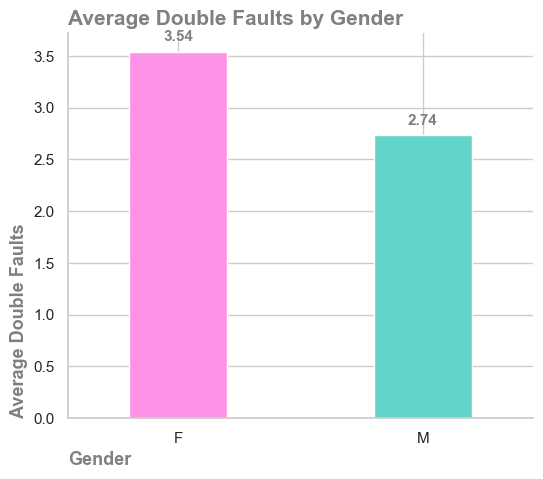

In [268]:
# Chart

final_result.plot(kind='bar', color=["#FD92E6", "#63D4CA"], figsize=(6,5), rot=0, width=0.4)

plt.title('Average Double Faults by Gender',loc='left' , color='gray' , weight='bold' , fontsize=15)

plt.ylabel('Average Double Faults' ,loc='bottom', color='gray' , weight='bold' , fontsize=13)
plt.xlabel('Gender' ,loc='left', color='gray' , weight='bold' , fontsize=13)

for i, v in enumerate(final_result):
    plt.text(i, v + 0.1, f"{v:.2f}", ha='center', fontweight='bold',color='gray', fontsize=11)
    
sns.despine(top=True, right=True)
ax.spines[["left" , "bottom"]].set_color("gray")

#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/avg_double_faults_simple.png', dpi=300, bbox_inches='tight')
plt.show()

# Question 9:

In [269]:
event= MatchEventInfo[["match_id", "winner_code", "start_datetime"]]
tornoment= MatchTournamentInfo[["match_id", "tournament_id", "tournament_name"]]
round_info= MatchRoundInfo[["match_id", "name", "slug"]] 
home= MatchHomeTeamInfo[["match_id", "player_id", "full_name"]].rename(columns={"player_id": "home_player_id", "full_name": "home_player_name"})
away= MatchAwayTeamInfo[["match_id", "player_id", "full_name"]].rename(columns={"player_id": "away_player_id", "full_name": "away_player_name"})

df_q9= (event.merge(tornoment, on= "match_id", how= "inner")
          .merge(round_info, on= "match_id", how= "inner")
          .merge(home, on= "match_id", how= "left")
          .merge(away, on= "match_id", how= "left")
    )

df_q9["start_datetime"]= pd.to_datetime(df_q9["start_datetime"], unit="s", errors="coerce") 
df_q9["YearMonth"] = df_q9['start_datetime'].dt.to_period('M')

In [270]:
finals_q9= df_q9[df_q9["name"].str.lower().eq("final") | df_q9["slug"].str.lower().eq("final")].copy()

In [271]:
finals_q9["winner_player_id"]= np.where(finals_q9["winner_code"]== 1, finals_q9["home_player_id"], finals_q9["away_player_id"])
finals_q9["winner_player_name"]= np.where(finals_q9["winner_code"]== 1, finals_q9["home_player_name"], finals_q9["away_player_name"])

In [272]:
wins_per_month= (finals_q9.groupby(["YearMonth", "winner_player_id", "winner_player_name"])["tournament_id"]
                          .nunique()
                          .reset_index(name="tournaments_won"))

In [273]:
result = wins_per_month.sort_values(["tournaments_won", "YearMonth"], ascending=[False, True]).head(10)
result

,YearMonth,winner_player_id,winner_player_name,tournaments_won
6,2024-02,50901.0,"Popko, Dmitry",3
46,2024-02,202572.0,"Gengel, Marek",3
132,2024-03,152766.0,"Helgo, Malene",3
165,2024-03,230049.0,"Jianu, Filip Cristian",3
197,2024-03,341818.0,"Faria, Jaime",3
204,2024-03,372311.0,"Nicod, Jakub",3
14,2024-02,79467.0,"Jasika, Omar",2
16,2024-02,82133.0,"Dellien Velasco, Murkel Alejandro",2
47,2024-02,205282.0,"Kužmová, Katarína",2
60,2024-02,231620.0,"Chidekh, Clement",2


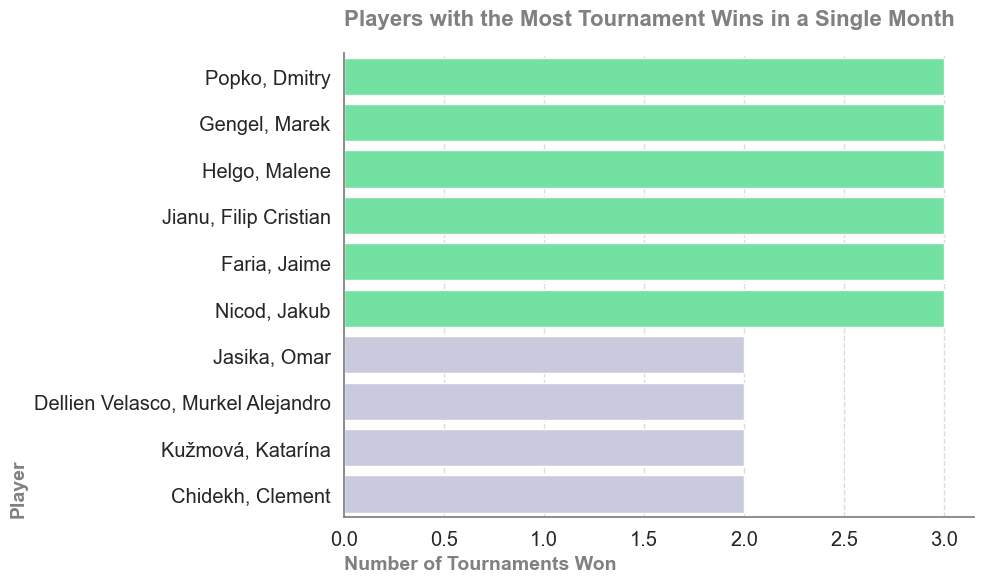

In [274]:
result_max = result["tournaments_won"].max()
colors = ["#60F39F" if x == result_max else "#c7c7e1" for x in result["tournaments_won"]]

fig, ax= plt.subplots(figsize= (10,6)) 
ax= sns.barplot(data= result ,x= "tournaments_won" ,y="winner_player_name" , hue="winner_player_name", palette= colors)

ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Players with the Most Tournament Wins in a Single Month", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_xlabel("Number of Tournaments Won", loc= "left", weight= "bold", color= "gray", fontsize= 14)
ax.set_ylabel("Player", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)

ax.tick_params(axis="x", color= "gray", labelsize= "large")
ax.tick_params(axis="y", color= "gray", labelsize= "large")

ax.grid(axis="x", linestyle= "dashed", alpha=0.7)

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Top Countries by Number of successful players.png", dpi=200)
plt.show()

**Observation**

* The highest number of tournaments_won in a single month is 3 championships.
* This record is shared by 6 players, so there is no single unique record holder.
* Out of these 6 players, 2 achieved this in February 2024 and 4 in March 2024; therefore, the records are concentrated in early 2024.
* The players with 3 championships in one month are:
    * Popko, Dmitry
    * Gengel, Marek
    * Helgo, Malene
    * Jianu, Filip Cristian
    * Faria, Jaime
    * Nicod, Jakub
* The next group of players had 2 championships in a month; this shows that the gap between the record holders and the next level is small, indicating tight competition.

**Conclusion**

The maximum number of tournament wins in a single month within this data is 3. This record is shared among several players and is not limited to one specific individual. The distribution of these records shows that in early 2024, several players managed to achieve a very successful and dense performance in a short period of time.

# Question 10

In [275]:
all_data = (pd.concat([MatchHomeTeamInfo[["player_id", "height", "current_rank"]], MatchAwayTeamInfo[["player_id", "height", "current_rank"]]])
                .dropna(subset=['height', 'current_rank']))

all_valid_height_and_rank = all_data.groupby('player_id').agg(
    height=('height', 'mean'),
    final_rank=('current_rank', 'last')
).reset_index()

all_valid_height_and_rank

,player_id,height,final_rank
0,14414,1.83,120.0
1,14486,1.85,652.0
2,14548,1.83,67.0
3,14844,1.93,45.0
4,14882,1.88,1.0
...,...,...,...
1329,463772,1.93,1224.0
1330,464370,1.80,1204.0
1331,483188,1.88,898.0
1332,487577,1.78,1284.0


In [276]:
correlation = all_valid_height_and_rank['height'].corr(all_valid_height_and_rank['final_rank'])
print(f"The correlation between height and ranking: {correlation:.4f}")

The correlation between height and ranking: 0.1022


**Observation**

* The calculated Pearson correlation coefficient between height and ranking is 0.1022.
* The value is positive, indicating that as height increases, there is a slight upward trend in the ranking value (note: in tennis, a “higher” numerical ranking actually represents a lower professional standing).
* However, the magnitude of the coefficient (0.1022) is extremely close to zero.

**Conclusion**

The result indicates a very weak positive correlation between a player’s height and their ranking. In statistical terms, a correlation this low suggests that height is not a significant predictor of professional success or ranking in this dataset. While there might be a negligible mathematical trend, the relationship is practically non-existent, implying that other factors—such as skill, technique, mental fortitude, and physical conditioning—play a far more dominant role in determining a player’s rank than their physical stature alone.

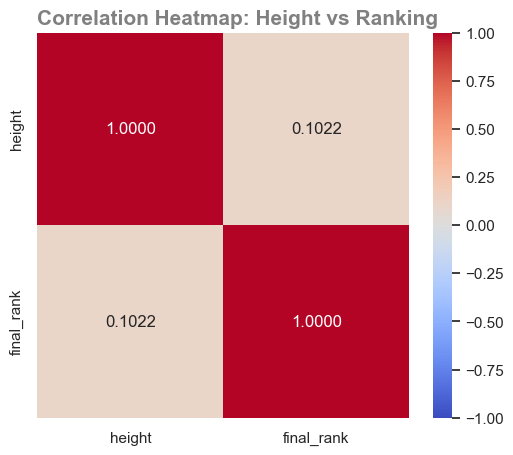

In [277]:
# Heatmap

corr_matrix = all_valid_height_and_rank[['height', 'final_rank']].corr()
plt.figure(figsize=(6,5),)

sns.heatmap (corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".4f",)

plt.title('Correlation Heatmap: Height vs Ranking',loc='left' , color='gray' , weight='bold' , fontsize=15)

#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Correlation Heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


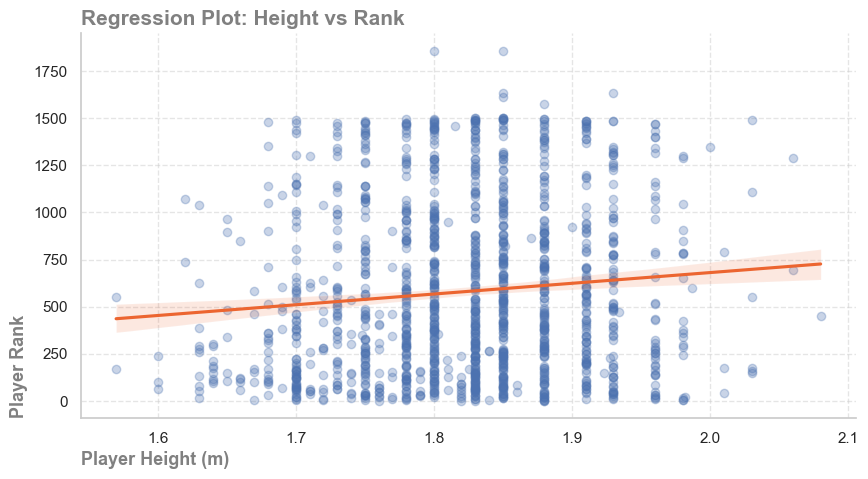

In [278]:
# Scatter plot
plt.figure(figsize=(10,5))

sns.regplot(
    data=all_valid_height_and_rank,x='height',y='final_rank',
    scatter_kws={'alpha':0.3},
    line_kws={'color':'#EC6530'}
)

plt.title('Regression Plot: Height vs Rank',loc='left' , color='gray' , weight='bold' , fontsize=15)

plt.xlabel('Player Height (m)', loc='left' , color='gray' , weight='bold' , fontsize=13)
plt.ylabel('Player Rank',loc='bottom' , color='gray' , weight='bold' , fontsize=13)

plt.grid(True, linestyle='--', alpha=0.5)

sns.despine(top=True, right=True)
ax.spines[["left" , "bottom"]].set_color("gray")

#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Regression Plot.png', dpi=300, bbox_inches='tight')
plt.show()

# Question 11

In [279]:
period_cols = ["period_1", "period_2", "period_3", "period_4", "period_5"]
print(f"MatchTimeInfo has {MatchTimeInfo["match_id"].duplicated().sum()} duplicated match_id values")
MatchTimeInfo[period_cols].isna().sum()

MatchTimeInfo has 0 duplicated match_id values


period_1     5784
period_2     5802
period_3    13482
period_4    16873
period_5    16873
dtype: int64

In [280]:
MatchTimeInfo = MatchTimeInfo.drop_duplicates(subset="match_id", keep="last")

MatchTimeInfo["total_duration"] = MatchTimeInfo[period_cols].sum(axis=1, skipna=True)

# Removing invalid values:
# - Negative 'period' or values exceeding 8 hours (world record for longest set).
# - Total duration less than 5 minutes (matches with no temporal data).
# - Total duration exceeding the world record (~11 hours)

MAX_PERIOD = 30000
MIN_DURATION = 300
MAX_TOTAL_DURATION = 44000

invalid_period = (MatchTimeInfo[period_cols] < 0).any(axis=1) | (MatchTimeInfo[period_cols] > MAX_PERIOD).any(axis=1)
invalid_duration = (MatchTimeInfo["total_duration"] < MIN_DURATION) | (MatchTimeInfo["total_duration"] > MAX_TOTAL_DURATION)

MatchTimeInfo_clean = MatchTimeInfo[~(invalid_period | invalid_duration)].copy()
MatchTimeInfo_clean

,match_id,period_1,period_2,period_3,period_4,period_5,current_period_start_timestamp,total_duration
5,11998448,2639.0,3090.0,NaN,NaN,NaN,1.706711e+09,5729.0
6,11998449,1500.0,2708.0,NaN,NaN,NaN,1.706727e+09,4208.0
7,11998450,1606.0,4771.0,2051.0,NaN,NaN,1.706738e+09,8428.0
8,11998451,3182.0,1960.0,2034.0,NaN,NaN,1.706793e+09,7176.0
15,11998672,4604.0,5172.0,3700.0,NaN,NaN,1.706752e+09,13476.0
...,...,...,...,...,...,...,...,...
35664,12213459,1876.0,3491.0,NaN,NaN,NaN,1.711982e+09,5367.0
35665,12213460,2813.0,2739.0,NaN,NaN,NaN,1.711980e+09,5552.0
35667,12213483,3330.0,3574.0,NaN,NaN,NaN,1.711983e+09,6904.0
35669,12213486,1968.0,3697.0,NaN,NaN,NaN,1.711981e+09,5665.0


In [281]:
average_seconds = MatchTimeInfo_clean['total_duration'].mean()
import datetime
average_time_form = str(datetime.timedelta(seconds=int(average_seconds)))
print(f"The average time of the matches: {average_time_form}")

The average time of the matches: 1:44:17


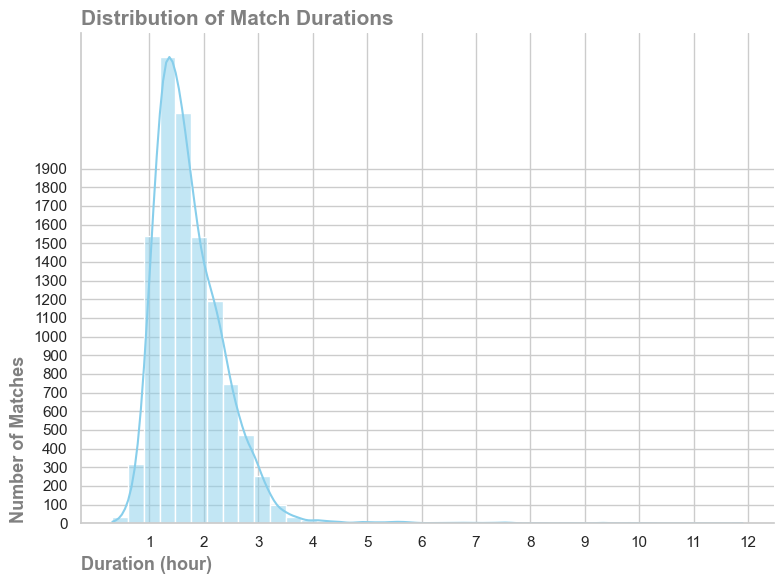

In [282]:
# Histogram
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8,6))

sns.histplot(MatchTimeInfo_clean['total_duration']/3600, bins=40, kde=True, color='skyblue')

plt.title('Distribution of Match Durations',loc='left' , color='gray' , weight='bold' , fontsize=15)

plt.xlabel('Duration (hour)', loc='left' , color='gray' , weight='bold' , fontsize=13)
plt.ylabel('Number of Matches', loc='bottom' , color='gray' , weight='bold' , fontsize=13)

plt.xticks(range(1,13))
plt.yticks(range(0,2000,100))

sns.despine(top=True, right=True)
ax.spines[["left" , "bottom"]].set_color("gray")

plt.tight_layout()
#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Match duration.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation**

* The data follows a right-skewed (or positively skewed) distribution. This is characterized by a high concentration of data points at the lower end of the scale and a “long tail” stretching toward the higher values.
* There is a significant concentration of matches within a relatively narrow window, with a clear modal peak occurring between 1.0 and 1.5 hours.
* Following the peak, there is a sharp decline in frequency. The probability of a match lasting longer than 2 hours decreases substantially.
* Outlier Analysis: While the distribution extends toward much higher durations, instances exceeding 4 hours are statistically rare, representing extreme outliers rather than typical match patterns.

**Conclusion**

The distribution confirms that the vast majority of tennis matches are characterized by efficiency, with most proceedings being consistently concluded within a window of under 3 hours. The heavy right-skew suggests that while the sport is capable of extreme endurance events (the “long tail”), these are exceptional occurrences rather than the norm. From a practical standpoint, this indicates that match duration is highly predictable for the bulk of the dataset, with high-duration matches serving as rare statistical exceptions rather than representative samples of standard play.

# __Question 12:__

In [283]:
all_matches = pd.concat([MatchAwayTeamInfo , MatchHomeTeamInfo], ignore_index=True)
all_matches = all_matches.drop_duplicates(subset='match_id' , keep='last')

In [284]:
df = pd.merge(GameInfo , all_matches[['gender','match_id']] , on='match_id' , how='inner')
df['gender'] = df['gender'].str.strip().str.upper()

In [285]:
df['gender'].isnull().sum()
df = df.dropna(subset=['gender'])

In [286]:
# Sets Played by Gender
home_gender = MatchHomeTeamInfo.set_index('match_id')['gender']
away_gender = MatchAwayTeamInfo.set_index('match_id')['gender']

gender_lookup = home_gender.combine_first(away_gender).reset_index()
gender_lookup

,match_id,gender
0,11998445,M
1,11998446,M
2,11998447,M
3,11998448,M
4,11998449,M
...,...,...
14192,12213458,M
14193,12213459,M
14194,12213460,M
14195,12213482,M


In [287]:
df  = pd.merge(GameInfo , gender_lookup[['gender','match_id']] , on='match_id' , how='inner')
df['gender'] = df['gender'].str.strip().str.upper()

In [288]:
game_per_set = df.groupby(['match_id' , 'set_id' , 'gender'])\
    .agg(games_per_set = ('game_id','nunique'))\
    .sort_values(by='games_per_set',ascending=False)
table = game_per_set.reset_index()
table

,match_id,set_id,gender,games_per_set
0,12168245,1,F,13
1,11998666,2,M,13
2,11998445,3,M,13
3,12063391,3,M,13
4,12063407,1,M,13
...,...,...,...,...
24013,12168239,3,F,1
24014,12168237,3,F,1
24015,12168236,3,F,1
24016,12168235,3,F,1


In [289]:
# A set must have atleast 6 games
unusual_sets = table[table['games_per_set'] < 6]
unusual_sets.count()

match_id         518
set_id           518
gender           518
games_per_set    518
dtype: int64

In [290]:
valid_sets = table[table['games_per_set'] >= 6]

In [291]:
avg_games_per_set = round(valid_sets['games_per_set'].mean() , 2)
avg_games_per_set_men = round(valid_sets[valid_sets['gender']=='M']['games_per_set'].mean() , 2)
avg_games_per_set_women = round(valid_sets[valid_sets['gender']=='F']['games_per_set'].mean() , 2)

print(f"Average games per set for all matches is {avg_games_per_set} .")
print(f"Average games per set for men's matches is {avg_games_per_set_men} and for women's matches is {avg_games_per_set_women} .")

Average games per set for all matches is 9.27 .
Average games per set for men's matches is 9.45 and for women's matches is 9.05 .


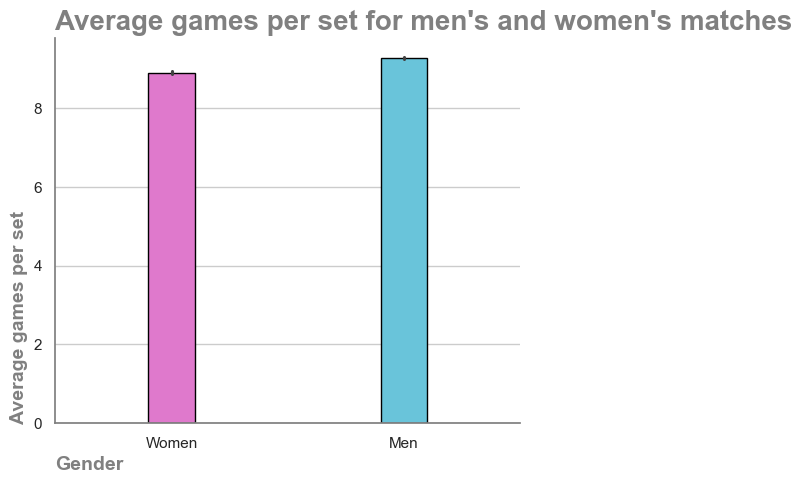

In [292]:
sns.set_style('whitegrid')

plt.figure(figsize=(6,5))
ax = sns.barplot(x='gender' , y='games_per_set',
            data=table,
            hue='gender',
            palette=("#f068d7" , "#56cfed"),
            edgecolor='black', width= 0.2
            )

plt.title("Average games per set for men's and women's matches",
          loc='left', 
          fontweight='bold', color='gray', fontsize=20)

plt.xlabel('Gender' , color='gray' , loc='left', weight='bold', fontsize=14)
plt.ylabel('Average games per set',loc='bottom' , weight='bold' , color='gray' , fontsize=14)

plt.xticks(['M','F'],['Men','Women'])

sns.despine(top=True, right=True)
ax.spines[["left" , "bottom"]].set_color("gray")

#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Average games per set.png', dpi=300, bbox_inches='tight')
plt.show()

__Observation__
* To ensure data accuracy, we excluded sets with fewer than 6 games, as they do not represent complete sets under standard tennis rules.
* The average number of games per set across all matches is 9.27
* Men's matches have a slightly higher average of 9.45 games per set, compared to women's matches with 9.05 games per set.

__Conclusion__  
The difference in average games per set between men (9.45) and women (9.05) is very small (0.40 games), indicating that match structure in terms of set length is largely similar across both genders in this dataset.

# __Question 13:__

In [293]:
all_players_raw = pd.concat([MatchAwayTeamInfo , MatchHomeTeamInfo] , ignore_index=True)
all_players_raw['plays'] = all_players_raw['plays'].str.strip()
all_players_raw['gender'] = all_players_raw['gender'].str.strip()

unique_players = all_players_raw.drop_duplicates(subset=['player_id'], keep='first')

In [294]:
unique_players = unique_players.dropna(subset=['plays'])

In [295]:
total = unique_players['plays'].count()
right_handed_players = unique_players[unique_players['plays']=='right-handed']['plays'].count()

In [296]:
left_handed_players = unique_players[unique_players['plays']=='left-handed']['plays'].count()

In [297]:
left_handed_percentage = round((left_handed_players/total)*100 , 2)
right_handed_percentage = round((right_handed_players/total)*100 , 2)
print(f'{left_handed_percentage}% of players are left handed and {right_handed_percentage}% of players are right handed')

11.61% of players are left handed and 88.39% of players are right handed


In [298]:
plays = unique_players['plays'].value_counts()
size = plays.values
labels = plays.index

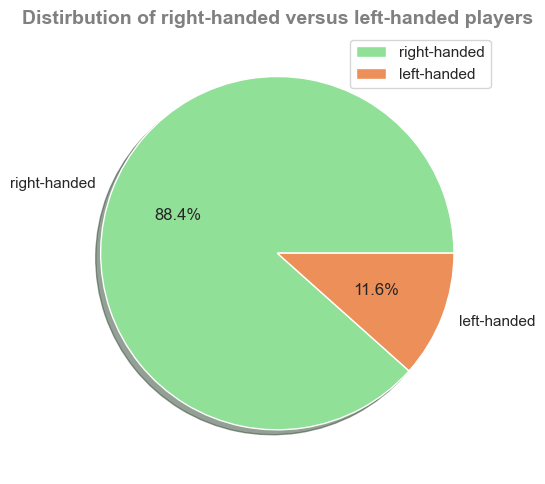

In [299]:
plt.figure(figsize=(6,5))
plt.pie(size , labels=labels , autopct='%1.1f%%',
        colors=['#90e098','#ed8f58'],
        shadow=True)
plt.title('Distirbution of right-handed versus left-handed players',color='gray', fontweight='bold', fontsize=14)

plt.legend()
plt.tight_layout()
#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Distirbution of right-handed versus left-handed players.png', dpi=300, bbox_inches='tight')
plt.show()

In [300]:
gender_play_counts = unique_players.groupby(['gender','plays']).agg(count = ('plays','count')).reset_index()
gender_play_counts

,gender,plays,count
0,F,left-handed,41
1,F,right-handed,367
2,M,left-handed,92
3,M,right-handed,646


In [301]:
total_per_gender = unique_players.groupby('gender').agg(total=('plays','count')).reset_index()
gender_play_counts = pd.merge(gender_play_counts , total_per_gender , on='gender')
gender_play_counts

,gender,plays,count,total
0,F,left-handed,41,408
1,F,right-handed,367,408
2,M,left-handed,92,738
3,M,right-handed,646,738


In [302]:
gender_play_counts['percentage'] = (gender_play_counts['count']/gender_play_counts['total'])*100 

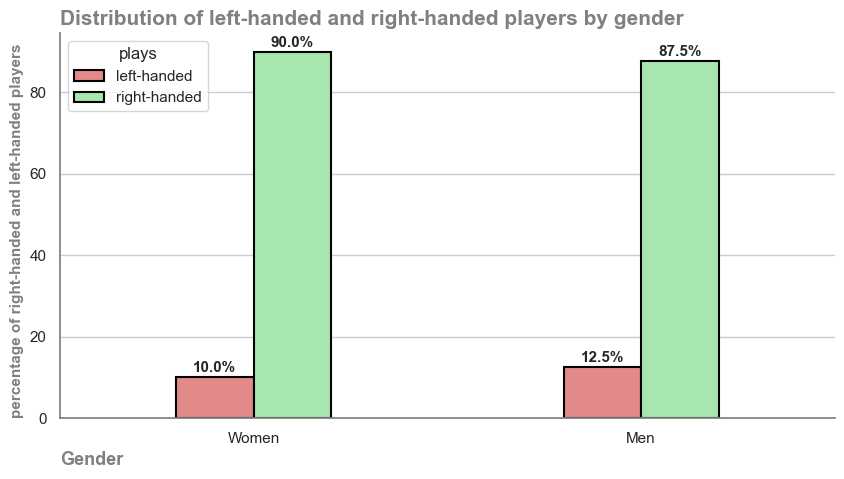

In [303]:
fif , ax = plt.subplots(figsize=(10,5))

sns.barplot(x='gender',
            y='percentage',
            hue='plays',
            data=gender_play_counts,
            palette=["#f17a7a","#9df0a4"],
            edgecolor='black',
            linewidth=1.5,
            dodge=True,
            width= 0.4
            )
plt.title('Distribution of left-handed and right-handed players by gender' , fontweight='bold' , color='gray',loc='left', fontsize=15)

plt.xlabel('Gender', fontsize=13 , color='gray',fontweight='bold', loc='left')
plt.ylabel('percentage of right-handed and left-handed players' , fontsize=11 , color='gray',fontweight='bold', loc='bottom')

plt.xticks(['F','M'],['Women' , 'Men'])

for bar in ax.patches:
    height=bar.get_height()
    if height>0:
        ax.text(
            bar.get_x() + bar.get_width()/2 , 
            height + 0.5,
            f'{height:.1f}%',
            ha='center',
            va='bottom',
            fontsize=11,
            fontweight='bold'
    )
        
sns.despine(right=True , top=True)
ax.spines[["left" , "bottom"]].set_color("gray")

#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Distirbution of right-handed versus left-handed players by gender.png', dpi=300, bbox_inches='tight')
plt.show()

__Observation__  
* Overall, 11.61% of players are left-handed, while 88.39% are right-handed.
* When broken down by gender, the pattern remains consistent:
   90% of female players are right-handed and 87.5% of male players are right-handed.
* The proportion of left-handed players is slightly higher among men (12.5%) compared to women (10%), though the difference is small.

__Conclusion__  
The data confirms that right-handed players are the clear majority in tennis, consistent with general population trends. While left-handed players are a minority in both genders, they are slightly more represented among men, though the difference is minimal.

# __Question 14:__

In [304]:
MatchTournamentInfo.head()

,match_id,tournament_id,tournament_name,tournament_slug,tournament_unique_id,tournament_category_name,tournament_category_slug,user_count,ground_type,tennis_points,has_event_player_statistics,crowd_sourcing_enabled,has_performance_graph_feature,display_inverse_home_away_teams,priority,competition_type
0,11974053,70826,Qualifiers,qualifiers,NaN,Davis Cup,davis-cup,6909,NaN,NaN,False,False,False,False,0,2.0
1,11974066,70826,Qualifiers,qualifiers,NaN,Davis Cup,davis-cup,6909,NaN,NaN,False,False,False,False,0,2.0
2,11998445,126168,"Montpellier, France",montpellier-france,NaN,ATP,atp,2155,Hardcourt indoor,250.0,False,False,False,False,0,2.0
3,11998446,126168,"Montpellier, France",montpellier-france,NaN,ATP,atp,2155,Hardcourt indoor,250.0,False,False,False,False,0,2.0
4,11998447,126168,"Montpellier, France",montpellier-france,NaN,ATP,atp,2155,Hardcourt indoor,250.0,False,False,False,False,0,2.0


In [305]:
MatchTournamentInfo.shape

(35671, 16)

In [306]:
MatchTournamentInfo.isnull().sum()

match_id                               0
tournament_id                          0
tournament_name                        0
tournament_slug                        0
tournament_unique_id               35671
tournament_category_name               0
tournament_category_slug               0
user_count                             0
ground_type                          562
tennis_points                      31667
has_event_player_statistics            0
crowd_sourcing_enabled                 0
has_performance_graph_feature          0
display_inverse_home_away_teams        0
priority                               0
competition_type                     485
dtype: int64

In [307]:
MatchTournamentInfo = MatchTournamentInfo.drop_duplicates(subset=['match_id'] , keep='last')
MatchTournamentInfo = MatchTournamentInfo.dropna(subset=['ground_type'])

In [308]:
MatchTournamentInfo['ground_type'] = MatchTournamentInfo['ground_type'].str.strip()

In [309]:
surface_used_in_tournaments = MatchTournamentInfo.groupby('ground_type').agg(count=('ground_type','count'))\
    .sort_values(by='count',ascending=False).reset_index()

surface_used_in_tournaments

,ground_type,count
0,Hardcourt outdoor,8093
1,Red clay,5583
2,Hardcourt indoor,2188
3,Grass,267
4,Red clay indoor,236
5,Carpet indoor,126
6,Synthetic outdoor,114
7,Green clay,18


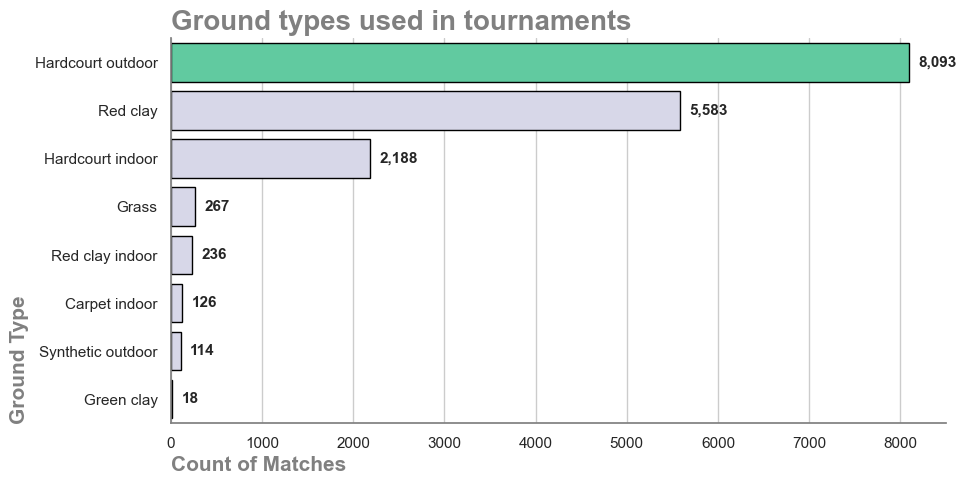

In [310]:
max_count = surface_used_in_tournaments["count"].max()
colors = ["#4FDCA3" if x == max_count else "#d4d4eb" for x in surface_used_in_tournaments["count"]]

plt.figure(figsize=(10,5))
ax = sns.barplot(
    x=surface_used_in_tournaments['count'],
    y=surface_used_in_tournaments['ground_type'],
    hue=surface_used_in_tournaments['ground_type'],
    palette=colors,
    data= surface_used_in_tournaments,
    edgecolor='black',
)
plt.title('Ground types used in tournaments' ,color='gray', weight='bold',loc='left', fontsize=20)

plt.xlabel('Count of Matches', weight='bold', color='gray', loc='left' , fontsize=15)
plt.ylabel('Ground Type', weight='bold', color='gray', loc='bottom' , fontsize= 15)

for bar in ax.patches:
    width = bar.get_width()
    ax.text(
        width + 100, 
        bar.get_y() + bar.get_height()/2,
        f'{int(width):,}',
        va='center',
        fontsize=11,
        fontweight='bold'
    )


sns.despine(right=True , top=True)
ax.spines[["left" , "bottom"]].set_color("gray")

#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Ground types used in tournaments.png', dpi=300, bbox_inches='tight')
plt.show()


In [311]:
MatchTournamentInfo.groupby(['ground_type','tournament_category_name']).agg(count=('ground_type','count')).sort_values(by='count' , ascending=False)

count
ground_type       tournament_category_name       
Hardcourt outdoor ITF Men                    3642
                  ITF Women                  2764
Red clay          ITF Men                    2649
                  ITF Women                  1878
Hardcourt indoor  ITF Women                   908
Red clay          Challenger                  743
Hardcourt indoor  ITF Men                     665
Hardcourt outdoor WTA                         589
                  Challenger                  480
                  ATP                         478
Hardcourt indoor  Challenger                  403
Red clay          ATP                         208
Grass             ITF Men                     145
Hardcourt indoor  ATP                         143
Hardcourt outdoor Challenger Women            140
Red clay indoor   ITF Women                   126
Grass             ITF Women                   122
Synthetic outdoor ITF Women                   114
Red clay indoor   ITF Men                     110
Red clay          Challenger Women             87
Carpet indoor     ITF Men                      79
Hardcourt indoor  WTA                          69
Carpet indoor     ITF Women                    47
Green clay        WTA                          18
Red clay          WTA                          18

__Observation__  
* The most common surface type across all tournaments is Hardcourt outdoor, with 8,093 matches, followed by Red clay with 5,583 matches.
* In contrast, surfaces like Green clay, Synthetic outdoor, and Carpet indoor are rarely used, each accounting for fewer than 200 matches.
* We calculated count of surface type used in tournaments per tournaments category and Hardcourt outdoor dominates in both ITF Men (3,642 matches) and ITF Women (2,764 matches).



__Conclusion__  
__Hardcourt outdoor__ is the dominant surface in the dataset, reflecting its widespread use across all tournament categories.  
 Red clay is the second most common surface, particularly in ITF and Challenger events, while grass and other surfaces are rarely used, indicating a strong preference for hardcourt and clay in professional tennis.

# __Question 15:__

In [312]:
unique_players['country'].isnull().sum()

np.int64(0)

In [313]:
unique_players = all_players_raw.drop_duplicates(subset=['player_id'], keep='first').copy()
unique_players['country'] = unique_players['country'].str.strip()

In [314]:
distinct_countries = unique_players.groupby('country').agg(DistinctCountries = ('country','nunique')).reset_index()
distinct_countries

,country,DistinctCountries
0,Algeria,1
1,Andorra,1
2,Antigua and Barbuda,1
3,Argentina,1
4,Australia,1
...,...,...
95,Uruguay,1
96,Uzbekistan,1
97,Venezuela,1
98,Vietnam,1


In [315]:
print(f"The number of distinct countries represented in the dataset is: {distinct_countries['country'].count()}")

The number of distinct countries represented in the dataset is: 100


In [316]:
unique_players.groupby('country').agg(players_per_country = ('player_id','size')).reset_index().sort_values(by='players_per_country',ascending=False)

,country,players_per_country
92,USA,225
44,Italy,205
31,France,202
77,Russia,137
47,Japan,124
...,...,...
75,Qatar,1
80,Singapore,1
78,Senegal,1
69,Pakistan,1


__Observation__  
* The dataset contains players from 100 distinct countries.
* The most represented countries are USA, Italy, France, Russia, and Japan.
* In contrast, countries such as Qatar, Singapore, Senegal, Pakistan, and Syria have only 1 player each.

__Conclusion__  
The data shows a wide global reach in professional tennis, with strong representation from traditional tennis powerhouse nations. At the same time, the presence of players from smaller or less prominent tennis countries highlights the sport's growing international diversity, even if some nations are minimally represented.



# __Question 16:__

In [317]:
MatchEventInfo = MatchEventInfo.drop_duplicates(subset=['match_id'],keep='last')
MatchHomeTeamInfo = MatchHomeTeamInfo.drop_duplicates(subset=['match_id', 'player_id'])
MatchAwayTeamInfo = MatchAwayTeamInfo.drop_duplicates(subset=['match_id', 'player_id'])

In [318]:
MatchHomeTeamInfo['role'] = 'home'
MatchAwayTeamInfo['role'] = 'away'

In [319]:
all_players_with_role = pd.concat([MatchHomeTeamInfo, MatchAwayTeamInfo], ignore_index=True)

In [320]:
home_rank = MatchHomeTeamInfo[['match_id','current_rank']].rename(columns={'current_rank':'home_rank'})
away_rank = MatchAwayTeamInfo[['match_id','current_rank']].rename(columns={'current_rank':'away_rank'})

In [321]:
all_players_with_role = pd.merge(all_players_with_role,home_rank , on='match_id' , how='left')
all_players_with_role = pd.merge(all_players_with_role , away_rank , on='match_id' , how='left')

In [322]:
player_stat = pd.merge(
    all_players_with_role,
    MatchEventInfo[['match_id', 'winner_code']],
    on='match_id',
    how='inner'
)

In [323]:
player_stat['opponent_rank'] = np.where(
    player_stat['role']=='home',
    player_stat['away_rank'],
    player_stat['home_rank']
)

In [324]:
player_stat = player_stat.dropna(subset=['opponent_rank'])
player_stat['opponent_rank'].isnull().sum()

np.int64(0)

In [325]:
player_stat[['player_id', 'full_name']].isnull().sum()

player_id    0
full_name    0
dtype: int64

In [326]:
player_stat['winner'] = (
    ((player_stat['role'] == 'home') & (player_stat['winner_code'] == 1)) |
    ((player_stat['role'] == 'away') & (player_stat['winner_code'] == 2))
)

In [327]:
top10_matches = player_stat[player_stat['opponent_rank'] <= 10]
top10_matches

,match_id,name,slug,gender,user_count,residence,birthplace,height,weight,plays,...,current_rank,name_code,country,full_name,role,home_rank,away_rank,winner_code,opponent_rank,winner
141,12021512,Bielinskyi V.,bielinskyi-viacheslav,M,250,NaN,DONETSK,NaN,NaN,NaN,...,499.0,BIE,Ukraine,"Bielinskyi, Viacheslav",home,499.0,10.0,NaN,10.0,False
201,12024041,Fomin S.,fomin-sergey,M,445,Uzbekistan,"Tashkent, Uzbekistan",1.80,80.0,right-handed,...,656.0,FOM,Uzbekistan,"Fomin, Sergey",home,656.0,8.0,2.0,8.0,False
295,12021514,Krutykh O.,krutykh-oleksii,M,868,NaN,Kiev,1.85,NaN,right-handed,...,370.0,KRU,Ukraine,"Krutykh, Oleksii",home,370.0,10.0,NaN,10.0,False
297,12028119,Orlov V.,orlov-vladyslav,M,499,"Kharkiv, Ukraine",Kharkiv,1.88,77.0,right-handed,...,602.0,ORL,Ukraine,"Orlov, Vladyslav",home,602.0,10.0,2.0,10.0,False
330,12024039,Sultanov K.,sultanov-khumoyun,M,467,"Namangan, Uzbekistan",Namangan,1.80,80.0,right-handed,...,354.0,SUL,Uzbekistan,"Sultanov, Khumoyun",home,354.0,8.0,NaN,8.0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23551,12157164,Marozsan F.,marozsan-fabian,M,5925,NaN,"Budapest, Hungary",1.93,NaN,right-handed,...,38.0,MAR,Hungary,"Marozsan, Fabian",away,5.0,38.0,1.0,5.0,False
23552,12157165,Dimitrov G.,dimitrov-grigor,M,28927,"Monte Carlo, Monaco","Haskovo, Bulgaria",1.91,81.0,right-handed,...,9.0,DIM,Bulgaria,"Dimitrov, Grigor",away,3.0,9.0,2.0,3.0,True
23553,12157174,Sinner J.,sinner-jannik,M,92881,"Monte Carlo, Monaco","San Candido, Italy",1.88,68.0,right-handed,...,2.0,SIN,Italy,"Sinner, Jannik",away,4.0,2.0,2.0,4.0,True
23658,12157166,Zverev A.,zverev-alexander,M,58013,"Monte Carlo, Monaco","Hamburg, Germany",1.98,90.0,right-handed,...,5.0,ZVE,Germany,"Zverev, Alexander",away,9.0,5.0,1.0,9.0,False


In [328]:
player_stats = top10_matches.groupby(['player_id','full_name']).agg(wins=('winner','sum'),total_matches=('match_id','count'))\
    .reset_index()
player_stats['win_rate'] = round((player_stats['wins']/player_stats['total_matches'])*100 , 2)
player_stats.sort_values(by=['win_rate','wins'],ascending=False).head(20)

,player_id,full_name,wins,total_matches,win_rate
86,185388,"Humbert, Ugo",3,3,100.0
106,228272,"Swiatek, Iga",3,3,100.0
7,19578,"Kerber, Angelique",1,1,100.0
13,36067,"Tsurenko, Lesia",1,1,100.0
24,47603,"Monteiro, Thiago",1,1,100.0
28,50641,"Vekić, Donna",1,1,100.0
36,59702,"Haddad Maia, Beatriz",1,1,100.0
38,64580,"Ćorić, Borna",1,1,100.0
44,69208,"Paolini, Jasmine",1,1,100.0
51,87690,"Thompson, Jordan",1,1,100.0


In [329]:
filtered_stats = player_stats[player_stats['total_matches'] > 2]
filtered_stats.sort_values(by='win_rate' , ascending=False)

,player_id,full_name,wins,total_matches,win_rate
86,185388,"Humbert, Ugo",3,3,100.00
106,228272,"Swiatek, Iga",3,3,100.00
85,179146,"Kalinskaya, Anna",4,5,80.00
100,206570,"Sinner, Jannik",3,4,75.00
126,275923,"Alcaraz, Carlos",3,4,75.00
53,89632,"Jarry, Nicolas",2,3,66.67
8,19728,"Cirstea, Sorana",2,3,66.67
107,230056,"Kostyuk, Marta",2,3,66.67
11,23581,"Dimitrov, Grigor",3,5,60.00
98,201239,"de Minaur, Alex",3,5,60.00


__Observation__  
* To ensure statistical reliability, we filtered matches where the opponent's rank was 10 or lower and applied a minimum threshold of 3 matches per player.
* After applying this filter, Ugo Humbert and Iga Swiatek both achieved a 100% win rate, having won all of their 3 matches against top‑10 opponents.
* Among players with more matches: Anna Kalinskaya won 4 out of 5 matches (80%). Carlos Alcaraz won 3 out of 4 matches(75%).

__Conclusion__  
Ugo Humbert and Iga Swiatek are the most successful players against top‑10 opponents in this dataset, with a 100% win rate.   
However, their perfect record is based on only 3 matches each, so while impressive, it should be interpreted with caution.  



# __Question 17:__

In [330]:
PowerInfo = PowerInfo.drop_duplicates()

In [331]:
PowerInfo.duplicated().sum()

np.int64(0)

In [332]:
break_stat = PowerInfo.groupby('match_id').agg(break_count = ('break_occurred','sum') , total_games_per_match=('game_num','size'))\
    .reset_index()
break_stat['break_rate%'] = round((break_stat['break_count']/break_stat['total_games_per_match'])*100 , 2)
break_stat = break_stat.sort_values(by='break_count',ascending=False)
break_stat.head(20)

,match_id,break_count,total_games_per_match,break_rate%
5472,12115163,36,71,50.70
5102,12109872,34,80,42.50
3745,12087307,33,66,50.00
6877,12145297,33,68,48.53
5140,12109940,33,58,56.90
3856,12088076,32,65,49.23
5467,12114926,31,63,49.21
5495,12116545,31,50,62.00
7051,12147768,30,55,54.55
5786,12124270,30,42,71.43


In [333]:
avg_break_per_match = round(break_stat['break_count'].mean() , 2)
print(f'The average number of breaks occurred per match is {avg_break_per_match}')

The average number of breaks occurred per match is 7.73


In [334]:
home_gender = MatchHomeTeamInfo.set_index('match_id')['gender']
away_gender = MatchAwayTeamInfo.set_index('match_id')['gender']

gender_lookup = home_gender.combine_first(away_gender).reset_index()
gender_lookup

,match_id,gender
0,11998445,M
1,11998446,M
2,11998447,M
3,11998448,M
4,11998449,M
...,...,...
14192,12213458,M
14193,12213459,M
14194,12213460,M
14195,12213482,M


In [335]:
power_with_gender = pd.merge(PowerInfo, gender_lookup[['match_id','gender']] , on='match_id' , how='inner')

In [336]:
power_with_gender = power_with_gender.dropna(subset=['gender'])
power_with_gender['gender'].isnull().sum()

np.int64(0)

In [337]:
power_male = power_with_gender[power_with_gender['gender']=='M']
power_female = power_with_gender[power_with_gender['gender']=='F']

In [338]:
female_break = power_female.groupby('match_id').agg(F_break_count = ('break_occurred','sum') , total_games=('game_num','size'))\
    .reset_index()
female_break['F_break_rate'] = round((female_break['F_break_count']/female_break['total_games'])*100 , 2)
female_break = female_break.sort_values(by='F_break_count',ascending=False)
avg_female_break = round(female_break['F_break_count'].mean() , 2)
female_break.head(10)

,match_id,F_break_count,total_games,F_break_rate
2331,12115163,36,71,50.70
1571,12087307,33,66,50.00
2327,12114926,31,63,49.21
2347,12116545,31,50,62.00
2470,12124266,30,68,44.12
2474,12124270,30,42,71.43
3012,12147918,30,57,52.63
2469,12124265,29,67,43.28
3002,12147562,29,43,67.44
2206,12110076,29,55,52.73


In [339]:
male_break = power_male.groupby('match_id').agg(M_break_count = ('break_occurred','sum') , total_games=('game_num','size'))\
    .reset_index()
male_break['M_break_rate'] = round((male_break['M_break_count']/male_break['total_games'])*100 , 2)
male_break = male_break.sort_values(by='M_break_count',ascending=False)
avg_male_break = round(male_break['M_break_count'].mean() , 2)
male_break.head(10)

,match_id,M_break_count,total_games,M_break_rate
2790,12109872,34,80,42.50
2821,12109940,33,58,56.90
3696,12145297,33,68,48.53
2152,12088076,32,65,49.23
2975,12117499,30,53,56.60
3773,12147768,30,55,54.55
3779,12147820,30,59,50.85
3777,12147790,30,60,50.00
5138,12175864,29,32,90.62
3678,12144538,29,57,50.88


In [340]:
print(f'The average number of breaks of serve per match for female matches is {avg_female_break} and for male matches is {avg_male_break}')

The average number of breaks of serve per match for female matches is 8.85 and for male matches is 6.8


__Observation__  
* On average, there are 7.73 breaks of serve per match across all matches in the dataset.
* Women's matches average 8.85 breaks per match.
* Men's matches average 6.80 breaks per match.

__Conclusion__  
The average number of breaks of serve per match = 7.73  
Women's matches show a noticeably higher number of breaks per match compared to men's matches. This difference may be attributed to generally stronger serves and higher hold percentages in men's tennis, which result in fewer break opportunities.

# __Optional Question 1:__
# Which player has the best win rate in tie‑breaks?

In [341]:
GameInfo = pd.read_csv(DATA_DIR / 'pbp.csv')
MatchAwayTeamInfo = pd.read_csv(DATA_DIR / 'away_team.csv')
MatchHomeTeamInfo = pd.read_csv(DATA_DIR / 'home_team.csv')
GameInfo = GameInfo.drop_duplicates().copy()
MatchHomeTeamInfo = MatchHomeTeamInfo.drop_duplicates(subset=['match_id', 'player_id']).copy()
MatchAwayTeamInfo = MatchAwayTeamInfo.drop_duplicates(subset=['match_id', 'player_id']).copy()

In [342]:
tiebreaks = GameInfo[GameInfo['scoring']==2]
last_points = tiebreaks.groupby(['match_id','set_id','game_id']).last().reset_index()

In [343]:
last_points['winner'] = np.where(
    last_points['home_score'] > last_points['away_score'] ,
    'home',
    'away'
)

In [344]:
home_players = MatchHomeTeamInfo[['match_id','player_id','full_name']].rename(
    columns={'player_id':'home_player_id' , 'full_name':'home_player_name'}
)

away_players = MatchAwayTeamInfo[['match_id','player_id','full_name']].rename(
    columns={'player_id':'away_player_id' , 'full_name':'away_player_name'}
)

In [345]:
tiebreaks_with_players = last_points.merge(home_players , on='match_id' , how='left')
tiebreaks_with_players = tiebreaks_with_players.merge(away_players , on='match_id' , how='left')

In [346]:
tiebreaks_with_players['home_player_name'] = tiebreaks_with_players['home_player_name'].replace('Arangia, Emiliana', 'Arango, Emiliana')
tiebreaks_with_players['away_player_name'] = tiebreaks_with_players['away_player_name'].replace('Arangia, Emiliana', 'Arango, Emiliana')

In [347]:
tiebreaks_with_players['winner_name'] = np.where(
    tiebreaks_with_players['winner']=='home',
    tiebreaks_with_players['home_player_name'],
    tiebreaks_with_players['away_player_name']
)

tiebreaks_with_players['winner_id'] = np.where(
    tiebreaks_with_players['winner'] == 'home',
    tiebreaks_with_players['home_player_id'],
    tiebreaks_with_players['away_player_id']
)

In [348]:
unique_wins = tiebreaks_with_players.drop_duplicates(subset=['match_id', 'set_id', 'game_id', 'winner_id'])

wins = tiebreaks_with_players.groupby(['winner_id']).size().reset_index(name='wins').sort_values(by='wins',ascending=False)
wins

,winner_id,wins
199,50901.0,334
1725,302567.0,212
1283,231597.0,210
1887,338890.0,207
1913,341818.0,205
...,...,...
1598,284060.0,1
722,151384.0,1
1977,367820.0,1
341,67430.0,1


In [349]:
home_tiebreaks = tiebreaks_with_players[['match_id','set_id','game_id','home_player_id','home_player_name']].rename(
    columns={'home_player_id':'player_id' , 'home_player_name':'full_name'}
)

away_tiebreaks = tiebreaks_with_players[['match_id','set_id','game_id','away_player_id','away_player_name']].rename(
    columns={'away_player_id':'player_id' , 'away_player_name':'full_name'}
)

all_tiebreaks_players = pd.concat([home_tiebreaks,away_tiebreaks], ignore_index=True)

tiebreaks_with_players['home_player_name'] = tiebreaks_with_players['home_player_name'].replace('Arangia, Emiliana', 'Arango, Emiliana')
tiebreaks_with_players['away_player_name'] = tiebreaks_with_players['away_player_name'].replace('Arangia, Emiliana', 'Arango, Emiliana')

all_tiebreaks_players = all_tiebreaks_players.drop_duplicates(subset=['player_id', 'match_id', 'set_id', 'game_id'])


total_tiebreaks = all_tiebreaks_players.groupby(['player_id','full_name']).size()\
    .reset_index(name='total_tiebreaks').sort_values(by='total_tiebreaks', ascending=False)
total_tiebreaks

,player_id,full_name,total_tiebreaks
213,50901.0,"Popko, Dmitry",406
1956,338890.0,"Merida Aguilar, Daniel",326
1788,302567.0,"Sakellaridis, Stefanos",306
1983,341818.0,"Faria, Jaime",291
1020,197809.0,"Clarke, Jay",289
...,...,...,...
2269,401410.0,"Cuoto, Lena",1
2350,416482.0,"Bochoradze, Anna",1
1999,347906.0,"Karner, Elena",1
656,122654.0,"Proctor, Lauren",1


In [350]:
final_stat = total_tiebreaks.merge(wins , left_on='player_id', right_on='winner_id' , how='left')
final_stat['wins'] = final_stat['wins'].fillna(0).astype(int)

final_stat['win_rate'] = round((final_stat['wins']/final_stat['total_tiebreaks'])*100 , 2)

In [351]:
filtered_final_stats = final_stat[final_stat['total_tiebreaks'] > 10].copy()
result_stats = filtered_final_stats.sort_values(by=['win_rate','wins'],ascending=False)
result_stats.head(10)

,player_id,full_name,total_tiebreaks,winner_id,wins,win_rate
1619,50655.0,"Friedsam, Anna-Lena",49,50655.0,49,100.0
1872,454995.0,"Bucea, Iulia",35,454995.0,35,100.0
1935,316921.0,"Salvi, Linda",31,316921.0,31,100.0
2105,190423.0,"Mane, Snehal",23,190423.0,23,100.0
2162,47810.0,"Khromacheva, Irina",20,47810.0,20,100.0
2188,337408.0,"Fruhvirtova, Brenda",18,337408.0,18,100.0
2198,326095.0,"Ibragimov, Daniel",18,326095.0,18,100.0
2200,340014.0,"Barrera Aguirre, Isabella",18,340014.0,18,100.0
2273,52244.0,"Balaji N., Sriram",13,52244.0,13,100.0
2285,450846.0,"Mrva, Maxim",13,450846.0,13,100.0


__Observation__  
* A naming inconsistency (Arangia vs Arango) was corrected to ensure accurate tie‑break statistics for Emiliana Arango.
* To identify the player with the best win rate in tie‑breaks, we filtered for games with scoring == 2 and required a minimum of 10 tie‑breaks played to ensure statistical reliability.
* Remarkably, all top 10 players achieved a 100% win rate in tie‑breaks.
* Anna‑Lena Friedsam leads the list, having won all 49 tie‑breaks she contested.
* Other players with perfect records include: Iulia Bucea (35/35), Linda Salvi (31/31) and Snehal Mane (23/23)

__Conclusion__  
A select group of players, led by Anna‑Lena Friedsam, achieved a perfect 100% win rate in tie‑breaks, showcasing their ability to perform under pressure. 

# __Optional Question 2:__
# Which surface type has the highest average number of aces?

In [352]:
aces_info = PeriodInfo[(PeriodInfo['statistic_name']=='aces')&(PeriodInfo['period']=='ALL')]
aces_info = aces_info.drop_duplicates(subset=['match_id'],keep='last')
aces_info['all_aces'] = aces_info['home_value'] + aces_info['away_value']

In [353]:
aces_with_ground_type = pd.merge(aces_info , MatchTournamentInfo[['match_id','ground_type']] , on='match_id' , how='inner')

In [354]:
avg_aces_per_surface = aces_with_ground_type.groupby('ground_type').agg(avg_aces = ('all_aces','mean')).reset_index()\
    .sort_values(by='avg_aces' , ascending=False)

avg_aces_per_surface

,ground_type,avg_aces
0,Carpet indoor,11.541667
1,Grass,9.416667
3,Hardcourt indoor,7.909789
4,Hardcourt outdoor,5.552816
2,Green clay,4.111111
6,Red clay indoor,3.871921
7,Synthetic outdoor,3.500000
5,Red clay,3.213890


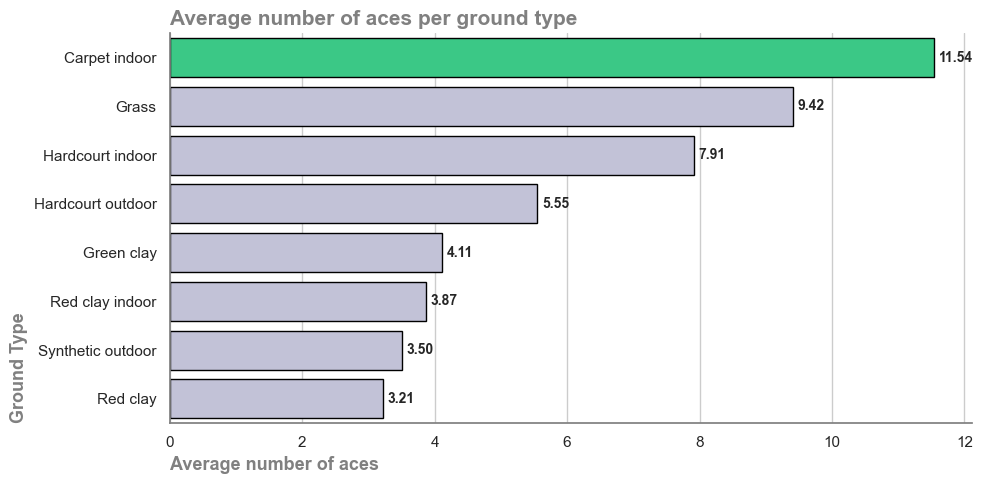

In [355]:
avg_aces_max = avg_aces_per_surface['avg_aces'].max()
colors = ["#23E088" if x == avg_aces_max else "#bfbfda" for x in avg_aces_per_surface['avg_aces']]
plt.figure(figsize=(10,5))
ax = sns.barplot(
    x=avg_aces_per_surface['avg_aces'],
    y=avg_aces_per_surface['ground_type'],
    hue=avg_aces_per_surface['ground_type'],
    data=avg_aces_per_surface,
    palette=colors,
    edgecolor='black'
    
)
plt.title('Average number of aces per ground type' , loc='left' , color='gray' , weight='bold' , fontsize=15)
plt.xlabel('Average number of aces' , loc='left' , color='gray' , weight='bold' , fontsize=13)
plt.ylabel('Ground Type' , loc='bottom' , color='gray' , weight='bold' , fontsize=13)

for bar in ax.patches:
    width = bar.get_width() 
    ax.text(
        width + 0.07,  
        bar.get_y() + bar.get_height()/2,  
        f'{width:.2f}',  
        va='center',
        fontsize=10,
        fontweight='bold'
    )
sns.despine(right=True , top=True)
ax.spines[["left" , "bottom"]].set_color("gray")

plt.tight_layout()
#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Average number of aces per ground type.png', dpi=300, bbox_inches='tight')
plt.show()

__Observation__  
* The surface type with the highest average number of aces per match is Carpet indoor, with an average of 11.54 aces per match.
* Grass ranks second with 9.42 aces per match, followed by Hardcourt indoor with 7.91 aces per match.
* In contrast, Red clay has the lowest average with only 3.21 aces per match.
* A bar chart was also created to visually represent these differences.

__Conclusion__  
The data confirms that faster surfaces such as carpet, grass, and indoor hard courts are associated with higher ace counts, while slower surfaces like clay produce significantly fewer aces. This pattern is consistent with the general understanding that surface speed directly affects serve effectiveness, with faster surfaces favoring powerful serves and slower surfaces encouraging longer rallies and fewer unreturnable serves.



# __Optional Question 3:__

## Is there a relationship between the player's BMI and their Total prize?

In [356]:
home_bmi = MatchHomeTeamInfo[["match_id", "player_id", "height", "weight","total_prize"]].copy()
home_bmi = home_bmi.rename(columns={"height": "home_height", "weight": "home_weight"})
away_bmi = MatchAwayTeamInfo[["match_id", "player_id", "height", "weight","total_prize"]].copy()
away_bmi = away_bmi.rename(columns={"height": "away_height", "weight": "away_weight"})

In [357]:
home_bmi["bmi"] = home_bmi["home_weight"] / (home_bmi["home_height"] ** 2)
away_bmi["bmi"] = away_bmi["away_weight"] / (away_bmi["away_height"] ** 2)

In [358]:
home_rows = home_bmi[["match_id", "player_id", "bmi", "total_prize"]]
away_rows = away_bmi[["match_id", "player_id", "bmi", "total_prize"]]

analysis_df = pd.concat([home_rows, away_rows], ignore_index=True).drop_duplicates()

In [359]:
player_level_df = analysis_df.groupby("player_id", as_index=False).agg(
    {"bmi": "mean", "total_prize": "mean"}
)
print(f"The number of unique players: {len(player_level_df)}")
player_level_df

The number of unique players: 2644


,player_id,bmi,total_prize
0,14414,23.589835,1.734196e+07
1,14486,24.835646,1.122164e+08
2,14548,24.187046,3.054042e+07
3,14844,22.819405,1.830074e+07
4,14882,21.785876,1.515179e+08
...,...,...,...
2639,489714,NaN,7.102000e+03
2640,490732,NaN,1.713333e+03
2641,498399,NaN,9.190000e+02
2642,499834,NaN,2.799100e+04


In [360]:
player_level_df["bmi"].describe()

count    663.000000
mean      22.478175
std        1.696570
min        8.659560
25%       21.499597
50%       22.550941
75%       23.510204
max       26.551437
Name: bmi, dtype: float64

In [361]:
player_level_df = player_level_df[(player_level_df["bmi"] >= 15) & (player_level_df["bmi"] <= 35)]

In [362]:
correlation = player_level_df['bmi'].corr(player_level_df['total_prize'])
print(f"The correlation is: {correlation:.3f}")

The correlation is: -0.061


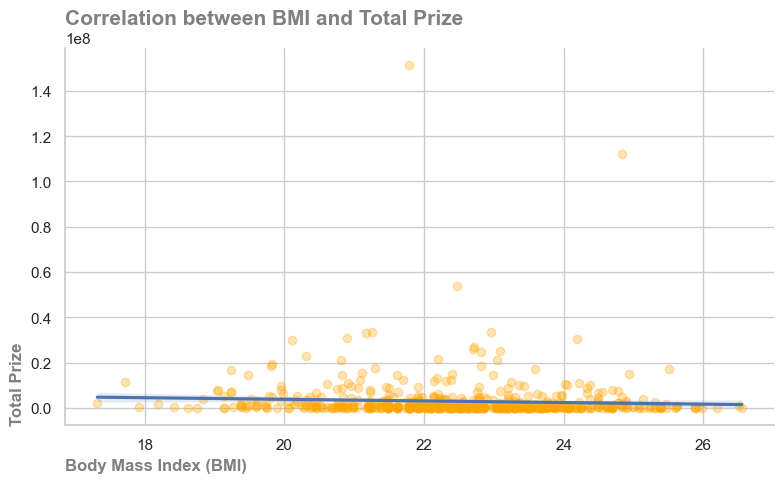

In [363]:
plt.figure(figsize=(8,5))
sns.regplot(
    x='bmi',
    y='total_prize',
    data= player_level_df,
    scatter_kws={'alpha':0.3, 'color':'orange'}
)
plt.title('Correlation between BMI and Total Prize', loc='left', fontsize=15, color='gray', fontweight='bold')
plt.xlabel('Body Mass Index (BMI)',loc='left', fontsize=12, color='gray', fontweight='bold')
plt.ylabel('Total Prize', loc='bottom', fontsize=12, color='gray', fontweight='bold')

sns.despine(right=True, top=True)
ax.spines[["left" , "bottom"]].set_color("gray")

plt.tight_layout()
#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Correlation between BMI and Total Prize.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation**

* The statistical calculation yields a Pearson correlation coefficient of −0.061.
* This value is extremely close to zero, indicating a negligible negative direction.

**Conclusion**

The relationship between the two variables is statistically insignificant. There is no observable linear pattern, meaning changes in one variable do not provide any predictive value for changes in the other. The variables can be considered effectively independent of each other.

# __Optional Question 4:__

## What is the win rate of players when serving first versus receiving first?

In [364]:
event_clean = MatchEventInfo[['match_id', 'first_to_serve', 'winner_code']].drop_duplicates(subset="match_id", keep="last")
df_serve_analysis = event_clean.dropna(subset=["first_to_serve", "winner_code"]).copy()

print(f"Data Coverage: {len(df_serve_analysis)} from {len(event_clean)} match "
      f"({len(df_serve_analysis)/len(event_clean)*100:.1f}%)")

def check_first_server_win(row):
    if row['first_to_serve'] == row['winner_code']:
        return 1  
    else:
        return 0  

df_serve_analysis['first_server_won'] = df_serve_analysis.apply(check_first_server_win, axis=1)

win_rate_first_server = df_serve_analysis['first_server_won'].mean() * 100
win_rate_receiver = (1 - df_serve_analysis['first_server_won'].mean()) * 100


print(f"Win Rate of First Server: {win_rate_first_server:.2f}%")
print(f"Win Rate of First Receiver: {win_rate_receiver:.2f}%")

Data Coverage: 11211 from 16873 match (66.4%)
Win Rate of First Server: 57.56%
Win Rate of First Receiver: 42.44%


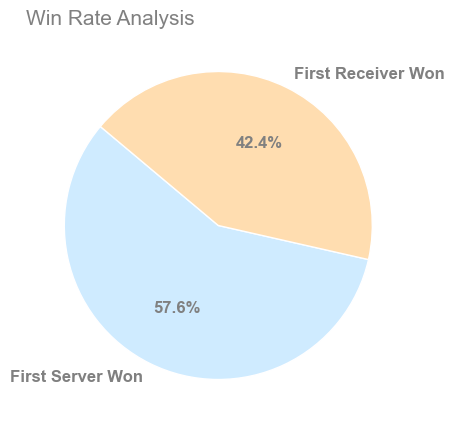

In [365]:
labels = ['First Server Won', 'First Receiver Won']
sizes = [win_rate_first_server,win_rate_receiver]
colors = ['#CFEBFF','#FFDDB0']
plt.figure(figsize=(6,5))

plt.pie(sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        textprops={'fontsize': 12,
                   'color': 'gray',
                   'fontweight': 'bold'})

plt.title('Win Rate Analysis', fontsize=15, color='gray', loc='left')

#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/win rate.png', dpi=300, bbox_inches='tight')
plt.show()

**Observation**

* The dataset covers 11,211 out of 16,873 matches, representing 66.4% of the total data.
* Within this coverage, the First Server achieves a win rate of 57.56%, while the First Receiver wins 42.44% of the points.

**Conclusion**

The data indicates a strong advantage for the player initiating the point via their serve. The server’s ability to win significantly more points than the receiver suggests favorable conditions for serving or effective strategies employed by servers in this dataset.

# __Optional Question 5:__

##  Which tournament surface is associated with the longest average match duration?

In [366]:
MatchTournamentInfo["ground_type"].value_counts()

ground_type
Hardcourt outdoor    8093
Red clay             5583
Hardcourt indoor     2188
Grass                 267
Red clay indoor       236
Carpet indoor         126
Synthetic outdoor     114
Green clay             18
Name: count, dtype: int64

In [367]:
MatchTournamentInfo_clean = (MatchTournamentInfo[['match_id', 'ground_type']].dropna(subset=['match_id', 'ground_type'])
                              .drop_duplicates(subset='match_id', keep='last'))

surface_duration = MatchTournamentInfo_clean.merge(MatchTimeInfo_clean[['match_id', 'total_duration']]
                                            .drop_duplicates(subset='match_id', keep='first'),on='match_id', how='inner')

avg_duration_surface = (surface_duration.groupby('ground_type')
                                        .agg(match_count=('match_id', 'nunique'),avg_duration_seconds=('total_duration', 'mean'))
                                        .sort_values('avg_duration_seconds', ascending=False))

avg_duration_surface['avg_duration_hours'] = (avg_duration_surface['avg_duration_seconds'] / 3600).round(2)

print(avg_duration_surface)

                   match_count  avg_duration_seconds  avg_duration_hours
ground_type                                                             
Red clay                  3295           6552.812443                1.82
Synthetic outdoor           77           6417.779221                1.78
Hardcourt outdoor         4962           6252.275897                1.74
Red clay indoor            199           6155.919598                1.71
Grass                      154           6149.688312                1.71
Green clay                  18           6078.333333                1.69
Carpet indoor              119           5895.974790                1.64
Hardcourt indoor          2023           5827.578843                1.62


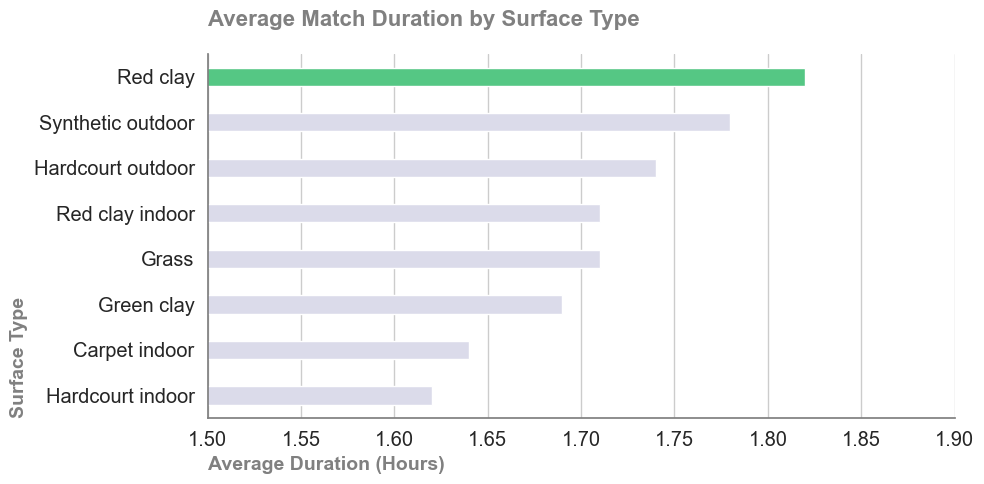

In [368]:
avg_duration_max = avg_duration_surface["avg_duration_hours"].max()
colors = ["#42DA81" if x == avg_duration_max else "#d8d8ed" for x in avg_duration_surface["avg_duration_hours"]]


fig, ax= plt.subplots(figsize= (10,5)) 
ax = sns.barplot(data= avg_duration_surface, x= "avg_duration_hours", y= "ground_type", hue= "ground_type", palette=colors, legend=False, width=0.4)

plt.xlim(1.5, 1.9)

ax.spines[["right" , "top"]].set_visible(False)
ax.spines[["left" , "bottom"]].set_color("gray")

ax.set_title("Average Match Duration by Surface Type", loc= "left", weight= "bold", color= "gray", fontsize= 16, pad=20)

ax.set_xlabel("Average Duration (Hours)", loc= "left", weight= "bold", color= "gray", fontsize= 14)
ax.set_ylabel("Surface Type", loc= "bottom", weight= "bold", color= "gray", fontsize= 14)

ax.tick_params(axis="x", color= "gray", labelsize= "large")
ax.tick_params(axis="y", color= "gray", labelsize= "large")

plt.tight_layout()
#plt.savefig("/home/mohmmad/zahra/daneshkar/tennis_final/figures/Average Match Duration by Surface Type.png", dpi=200)
plt.show()

**Observation**

* Average match duration by court surface shows that Red clay had the longest matches, with a mean duration of 1.82 hours.
* It was followed by Synthetic outdoor at 1.78 hours and Hardcourt outdoor at 1.74 hours.
* Red clay indoor and Grass both recorded average durations of about 1.71 hours.
* The shortest average match duration was observed on Hardcourt indoor at 1.62 hours, while Carpet indoor was also among the faster surfaces at 1.64 hours.
* The difference between the longest and shortest surfaces is about 0.20 hours, or roughly 12 minutes.
* In terms of sample size, the estimates for Hardcourt outdoor (4,962 matches), Red clay (3,295 matches), and Hardcourt indoor (2,023 matches) are more reliable, whereas surfaces such as Green clay (18 matches) and Synthetic outdoor (77 matches) should be interpreted more cautiously.

**Conclusion**

Matches played on Red clay tend to last longer on average, which is consistent with the technical nature of clay courts. Clay generally slows the ball down and produces longer rallies. In contrast, Hardcourt indoor and Carpet indoor are among the fastest surfaces, so matches on them usually finish in less time. However, the overall spread in average duration is not very large, which suggests that surface type matters but is not the only factor affecting match length.

# __Optional Question 6:__

## Are higher-ranked players more likely to win matches?

In [369]:
home_rank = (
    MatchHomeTeamInfo[["match_id", "player_id", "current_rank"]]
    .dropna(subset=["match_id", "player_id", "current_rank"])
    .drop_duplicates(subset="match_id", keep="first")
    .rename(columns={
        "player_id": "player_id_home",
        "current_rank": "current_rank_home"
    })
)

away_rank = (
    MatchAwayTeamInfo[["match_id", "player_id", "current_rank"]]
    .dropna(subset=["match_id", "player_id", "current_rank"])
    .drop_duplicates(subset="match_id", keep="first")
    .rename(columns={
        "player_id": "player_id_away",
        "current_rank": "current_rank_away"
    })
)

In [370]:
event_rank = (
    MatchEventInfo[["match_id", "winner_code"]]
    .dropna(subset=["match_id", "winner_code"])
    .drop_duplicates(subset="match_id", keep="first")
    .merge(home_rank, on="match_id", how="left")
    .merge(away_rank, on="match_id", how="left")
)

In [371]:
event_rank_clean = event_rank.dropna(subset=["current_rank_home", "current_rank_away"])

event_rank_clean["better_rank_side"] = np.where(
    event_rank_clean["current_rank_home"] < event_rank_clean["current_rank_away"],
    "home",
    np.where(
        event_rank_clean["current_rank_home"] > event_rank_clean["current_rank_away"],
        "away",
        "equal"
    )
)

event_rank_clean["winner_side"] = np.where(
    event_rank_clean["winner_code"] == 1,
    "home",
    "away"
)

event_rank_clean["better_rank_won"] = np.where(
    event_rank_clean["better_rank_side"] == "equal",
    np.nan,
    event_rank_clean["better_rank_side"] == event_rank_clean["winner_side"]
)

C:\Users\Admin\AppData\Local\Temp\ipykernel_19400\1128279409.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_rank_clean["better_rank_side"] = np.where(
C:\Users\Admin\AppData\Local\Temp\ipykernel_19400\1128279409.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  event_rank_clean["winner_side"] = np.where(
C:\Users\Admin\AppData\Local\Temp\ipykernel_19400\1128279409.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_i

In [372]:
better_rank_win_rate = (event_rank_clean["better_rank_won"].mean() * 100).round(2)
print(f"better_rank_win_rate: {better_rank_win_rate}")

better_rank_win_rate: 64.92


**Observation**

* The win rate of the better-ranked player was 64.9%.

* This means that in roughly two-thirds of the matches, the player with the lower pre-match rank number (i.e., the better ranking) won the match.

* In contrast, about 35.1% of the matches were won by the lower-ranked player.

* Therefore, although ranking is clearly related to match outcome, it is not a perfect predictor of the winner.

**Conclusion**

The results show that players with a better ranking have a significantly higher chance of winning. However, since more than one-third of the matches were still won by the lower-ranked player, ranking alone is not sufficient to predict the result with certainty.

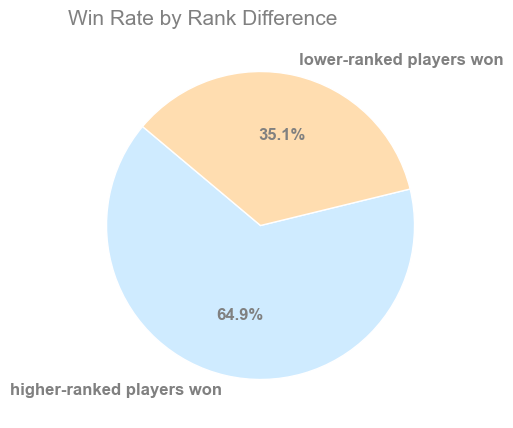

In [373]:
labels = ['higher-ranked players won', 'lower-ranked players won']
sizes = [better_rank_win_rate,(100 - better_rank_win_rate)]
colors = ['#CFEBFF','#FFDDB0']
plt.figure(figsize=(6,5))

plt.pie(sizes,
        labels=labels,
        autopct='%1.1f%%',
        startangle=140,
        colors=colors,
        textprops={'fontsize': 12,
                   'color': 'gray',
                   'fontweight': 'bold'})

plt.title('Win Rate by Rank Difference', fontsize=15, color='gray', loc='left')

#plt.savefig('/home/mohmmad/zahra/daneshkar/tennis_final/figures/Win Rate by Rank Difference.png', dpi=300, bbox_inches='tight')
plt.show()